# 80. Pooled calibration 6D: IMU-gauge relative regression (002.27 initialization)

Single-window fine-tuning. No classifier, no rollout. Preserve the original model, physical augmentation, datasets and left-multiplicative update convention. Let $C_i=R_i^{true}(R_i^{prior})^T$ and $c_i=\tau_i^{true}-\tau_i^{prior}$. Supervise $Q_i=C_0^TC_i$ and $q_i=c_i-c_0$, with IMU (index 0) as reference. Its target is identity / zero, and its inference output is always replaced with identity / zero. `IMU_IDENTITY_LOSS_WEIGHT=1` also supervises the raw reference head; set it to 0 for strictly N-1 supervised outputs. Time supervision uses signed relative offsets, not magnitudes.

The original 002.27 weights are loaded unchanged; their outputs initially have absolute semantics. After fine-tuning, the LiDAR outputs are interpreted directly as relative corrections (do not subtract the raw IMU prediction again). Relative accuracy and absolute recovery are reported separately. Absolute recovery chooses the SO(3) medoid of the three relative rotations and subtracts the ordinary median relative time correction. This is exact with perfect relative predictions under K<=1, but is only a sparse-fault prior for other cases. An oracle gauge is provided for diagnosis only, never for checkpoint deployment or fault detection.

Evaluation compares original 002.27, 002.27 with the same medoid rule, initialization interpreted as relative, and trained relative checkpoints on the same physical windows / injected cases. Every score is computed from individual predictions, not thresholded averages. No test-based selection.

## 1. Imports

In [1]:
from pathlib import Path
import json
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import roc_auc_score, average_precision_score

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / 'src' / 'obscalib').is_dir():
        ROOT = candidate
        break
else:
    raise FileNotFoundError('Run inside nn-obs-calib or one of its subdirectories.')
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs, make_kaist_dataloader
from obscalib.augmentations.config import (AugmentationConfig, CalibrationEventConfig, CommonBodyFrameRandomizationConfig, FrameRandomizationConfig, NoiseAugmentationConfig, PerturbationMagnitudeConfig, PriorPerturbationConfig, SamplingRateAugmentationConfig, SensorTopologyAugmentationConfig, TrueCalibrationAugmentationConfig)
from obscalib.augmentations.pipeline import AugmentationPipeline
from obscalib.calibration.state import CalibrationState
from obscalib.config import CalibrationPoolerConfig, MLPConfig, PooledCalibrationHeadConfig, PooledCalibrationModelConfig, TransformerConfig, WindowingConfig
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.data.structures import SensorStreamBatch, WindowBatch
from obscalib.geometry.lie import so3_exp
from obscalib.geometry.processing import GeometryProcessor
from obscalib.models.pooled_calibration_6d_model import PooledCalibration6DModel
import torch.nn.functional as F
import gc
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.training.checkpoint import load_training_checkpoint, save_training_checkpoint

print('Repository:', ROOT, '| PyTorch:', torch.__version__, '| CUDA:', torch.cuda.is_available())

Repository: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib | PyTorch: 2.7.1+cu126 | CUDA: True


## 2. Configuration

In [16]:
CHECKPOINT_PATH = ROOT / 'runs' / 'kaist_pooled_calibration_6d_002.27_full_rotation_regression' / 'best.pt'
RUN_NAME = 'kaist_relative_regression_6d_007.1_002.27'
RUN_DIR = ROOT / 'runs' / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)
RESUME_TRAINING = False
RUN_SMOKE_TEST = True
RUN_STOCHASTIC_TEST = True
RUN_STOCHASTIC_CHECKPOINT_EVALUATION = True
RUN_FULL_TRAINING = True
RUN_DETAILED_EVALUATION = True
RUN_TEST_EVALUATION = False  # Enable only after choosing the experiment on validation.
RUN_CONTROLLED_SWEEP = True

RANDOM_SEED = 80_0027
TRAIN_AUG_SEED, VALIDATION_AUG_SEED, TEST_AUG_SEED = 78_1001, 78_2002, 78_3003
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
MODEL_DTYPE = torch.float32
CALIBRATION_KEYS = ('imu', 'lidar', 'lidar_right')
REFERENCE_KEY = 'imu'
REFERENCE_INDEX = CALIBRATION_KEYS.index(REFERENCE_KEY)
TRAIN_NAMES = ('Urban08', 'Urban12', 'Urban13', 'Urban14', 'Urban15', 'Urban16')
VAL_NAMES = ('Urban26', 'Urban28')
TEST_NAMES = ('Urban38', 'Urban39')
assert len(set(TRAIN_NAMES + VAL_NAMES + TEST_NAMES)) == len(TRAIN_NAMES + VAL_NAMES + TEST_NAMES)
KAIST_DATASET_ROOT = Path('/mnt/d/Downloads/MobRobLab/KAISTDataset')
LIDAR_POSE_ROOT = Path('/home/camel/Skoltech/phd_proposal/data/KAISTDataset')
WINDOW_DURATION_S, WINDOW_STRIDE_S, MAX_SAMPLES_PER_SENSOR = 5.0, 5.0, 700
BATCH_SIZE = 32
GRADIENT_ACCUMULATION_STEPS = 1
TRAIN_CASES_PER_PHYSICAL = 4
PHYSICAL_WINDOWS_PER_UPDATE = BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS // TRAIN_CASES_PER_PHYSICAL
NUM_WORKERS = 0
NUM_EPOCHS = 200
MONITOR_WINDOWS_PER_VAL_SEQUENCE = 64
DETAILED_WINDOWS_PER_SEQUENCE = 250
SWEEP_WINDOWS_PER_SEQUENCE = 24
SWEEP_AXIS_REPEATS = 2
SWEEP_ANGLES_DEG = (0., 1., 2., 3., 3.5, 4., 5., 7.5, 10., 15., 20., 30., 45., 60., 75., 90., 120., 150., 179.)
SWEEP_TIMES_MS = (0., 2., 5., 10., 15., 20., 30., 50., 75., 100., 150.)

# Single-window pretrained fine-tuning; higher head LR because output semantics change.
LR_TRANSFORMER, LR_POOLER, LR_SHARED_MLP = 1e-5, 2e-5, 2e-5
LR_REGRESSION_HEAD = 1e-4
WEIGHT_DECAY, GRADIENT_CLIP_NORM = 1e-4, 1.0
LR_REDUCTION_FACTOR, LR_PATIENCE_EPOCHS, MIN_LR = 0.5, 8, 1e-7
PRINT_EVERY_BATCHES = 500

# Relative regression loss. IMU identity/zero target is explicitly supervised by default.
# Set IMU_IDENTITY_LOSS_WEIGHT=0.0 for N-1-only loss; inference always uses I / 0.
IMU_IDENTITY_LOSS_WEIGHT = 1.0
REG_ROT_WEIGHT, REG_TIME_WEIGHT = 1.0, 1.0
REG_ROT_SCALE_DEG, REG_TIME_SCALE_MS = 60.0, 50.0
GT_ROT_TOL_DEG, GT_TAU_TOL_MS = 3.0, 10.0

# Training sampling: original 78 distribution, with no additional hard-fault branch.
K_PROBABILITIES = (0.05, 0.85, 0.05, 0.05)
FAULT_COUNTS = (0, 1, 2, 3)
FAULT_MODES = ('rotation_only', 'time_only', 'both')
ROTATION_BINS_DEG = ((0.2, 1.), (1., 2.), (2., 3.), (3., 4.), (4., 5.), (5., 15.), (15., 45.), (45., 90.), (90., 150.), (150., 179.))
TIME_BINS_MS = ((2., 10.), (10., 30.), (30., 50.), (50., 75.), (75., 100.), (100., 150.))
TRUE_CALIBRATION_ROTATION_MAX_DEG, TRUE_CALIBRATION_TAU_MAX_S = 180.0, 0.030

STOCHASTIC_STEPS = 1000
STOCHASTIC_PHYSICAL_WINDOWS = 64
STOCHASTIC_MONITOR_WINDOWS_PER_SEQUENCE = 16
STOCHASTIC_ASSESSMENT_WINDOWS_PER_SEQUENCE = 32
STOCHASTIC_PRINT_EVERY = 25
SHOW_PLOTS, SAVE_PLOTS, PLOT_DPI = True, True, 150
BEST_CHECKPOINT_PATH = RUN_DIR / 'best.pt'  # Lowest relative objective (non-reference heads).
BEST_ABSOLUTE_PATH = RUN_DIR / 'best_absolute.pt'  # Lowest K0/K1 recovered absolute error.
LAST_CHECKPOINT_PATH = RUN_DIR / 'last.pt'
STOCHASTIC_BEST_PATH = RUN_DIR / 'stochastic_best.pt'
STOCHASTIC_BEST_ABSOLUTE_PATH = RUN_DIR / 'stochastic_best_absolute.pt'
STOCHASTIC_FINAL_PATH = RUN_DIR / 'stochastic_final.pt'

assert CALIBRATION_KEYS[0] == REFERENCE_KEY and len(CALIBRATION_KEYS) == 3
assert BATCH_SIZE > 0 and GRADIENT_ACCUMULATION_STEPS >= 1 and TRAIN_CASES_PER_PHYSICAL >= 1
assert BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS % TRAIN_CASES_PER_PHYSICAL == 0
assert PHYSICAL_WINDOWS_PER_UPDATE >= 1
assert np.isclose(sum(K_PROBABILITIES), 1) and min(K_PROBABILITIES) >= 0
assert min(REG_ROT_SCALE_DEG, REG_TIME_SCALE_MS) > 0 and IMU_IDENTITY_LOSS_WEIGHT >= 0
assert min(REG_ROT_WEIGHT, REG_TIME_WEIGHT) >= 0 and REG_ROT_WEIGHT + REG_TIME_WEIGHT > 0
assert CHECKPOINT_PATH.is_file(), CHECKPOINT_PATH
if hasattr(torch.backends, 'mha'): torch.backends.mha.set_fastpath_enabled(False)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if DEVICE.type == 'cuda': torch.cuda.manual_seed_all(RANDOM_SEED)
print('GPU batch:', BATCH_SIZE, '| optimizer batch:', BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS, '| device:', DEVICE)
print('Original 002.27:', CHECKPOINT_PATH, '| run:', RUN_DIR)


def clear_cuda():
    gc.collect()
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()


def finish_figure(fig, name):
    fig.tight_layout()
    if SAVE_PLOTS: fig.savefig(RUN_DIR / name, dpi=PLOT_DPI, bbox_inches='tight')
    if SHOW_PLOTS: plt.show()
    plt.close(fig)

GPU batch: 32 | optimizer batch: 32 | device: cuda
Original 002.27: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_6d_002.27_full_rotation_regression/best.pt | run: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_relative_regression_6d_007.1_002.27


## 3. KAIST datasets and fixed validation / test splits

In [3]:
T_B_L = np.array([
    [-0.514066, -0.702201, -0.492595, -0.440699],
    [ 0.486485, -0.711672,  0.506809,  0.397052],
    [-0.706447,  0.0208933, 0.707457,  1.90953],
    [0., 0., 0., 1.],
], dtype=float)
T_B_L_right = np.array([
    [-0.512152,  0.699241, -0.498761, -0.449885],
    [-0.494811, -0.714859, -0.494104, -0.416713],
    [-0.702041, -0.0062642, 0.712109, 1.91294],
    [0., 0., 0., 1.],
], dtype=float)
T_I_B = np.array([[1.,0.,0.,-0.07], [0.,1.,0.,0.], [0.,0.,1.,1.7], [0.,0.,0.,1.]])
rig_calibration = KAISTRigCalibration(
    T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, T_B_L_right=T_B_L_right,
    tau_imu_s=0.0, tau_lidar_s=-0.025, tau_lidar_right_s=-0.035,
)
windowing_config = WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR)
all_names = list(TRAIN_NAMES + VAL_NAMES + TEST_NAMES)
specs = build_kaist_sequence_specs(sequence_names=all_names, kaist_dataset_root=KAIST_DATASET_ROOT, lidar_pose_root=LIDAR_POSE_ROOT, lidar_right_pose_filename='lidar_map_poses_vlp_right.csv')
for spec in specs:
    if spec.lidar_right_pose_csv is None or not spec.lidar_right_pose_csv.is_file():
        raise FileNotFoundError(f'Missing right LiDAR odometry for {spec.name}: {spec.lidar_right_pose_csv}')
spec_by_name = {spec.name: spec for spec in specs}

def make_kaist_dataset(names):
    return KAISTCalibrationDataset([spec_by_name[name] for name in names], rig_calibration, windowing_config,
                                   measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)

train_dataset = make_kaist_dataset(TRAIN_NAMES)
val_dataset = make_kaist_dataset(VAL_NAMES)
test_dataset = make_kaist_dataset(TEST_NAMES)
for label, dataset in [('train', train_dataset), ('validation', val_dataset), ('test', test_dataset)]:
    assert tuple(dataset.calibration_keys) == CALIBRATION_KEYS, label
    print(label, 'windows=', len(dataset), '|', dataset.summary())

train_shuffle_generator = torch.Generator().manual_seed(RANDOM_SEED + 25)
train_loader = make_kaist_dataloader(train_dataset, batch_size=PHYSICAL_WINDOWS_PER_UPDATE, shuffle=True, drop_last=False, num_workers=NUM_WORKERS, generator=train_shuffle_generator)
print('Training physical batches:', len(train_loader))

# Validation indices are sampled once, then never shuffled between epochs.
# Use explicit split names, do not infer from dataset internal properties if unavailable.
def select_spread_indices_by_names(dataset, names, per_sequence, seed):
    rng = np.random.default_rng(seed)
    output = []
    for seq in names:
        available = np.asarray(dataset.window_indices_for_sequence(seq), dtype=int)
        count = len(available) if per_sequence is None else min(int(per_sequence), len(available))
        if not count:
            raise ValueError(f'No available windows for {seq}')
        if count == len(available):
            chosen = available
        else:
            edges = np.linspace(0, len(available), count + 1, dtype=int)
            chosen = available[[int(rng.integers(lo, hi)) for lo, hi in zip(edges[:-1], edges[1:])]]
        output.extend(chosen.tolist())
    return np.asarray(output, dtype=int)

monitor_val_indices = select_spread_indices_by_names(val_dataset, VAL_NAMES, MONITOR_WINDOWS_PER_VAL_SEQUENCE, RANDOM_SEED + 31)
detailed_val_indices = select_spread_indices_by_names(val_dataset, VAL_NAMES, DETAILED_WINDOWS_PER_SEQUENCE, RANDOM_SEED + 33)
detailed_test_indices = select_spread_indices_by_names(test_dataset, TEST_NAMES, DETAILED_WINDOWS_PER_SEQUENCE, RANDOM_SEED + 35)
print('Fixed validation monitor:', len(monitor_val_indices), '| detailed validation:', len(detailed_val_indices), '| final test:', len(detailed_test_indices))

train windows= 2006 | KAISTCalibrationDataset: 2006 windows from 6 sequences
approximate tensor storage: 44.0 MiB
  Urban08: windows=59, duration=297.8s, IMU=30800, LiDAR=2952, right LiDAR=2953
  Urban12: windows=473, duration=2478.6s, IMU=249198, LiDAR=23222, right LiDAR=23223
  Urban13: windows=223, duration=1446.5s, IMU=145492, LiDAR=10536, right LiDAR=10535
  Urban14: windows=286, duration=1737.0s, IMU=174681, LiDAR=13638, right LiDAR=13639
  Urban15: windows=184, duration=1034.3s, IMU=104795, LiDAR=9011, right LiDAR=9011
  Urban16: windows=781, duration=4458.1s, IMU=449215, LiDAR=37703, right LiDAR=37704
validation windows= 418 | KAISTCalibrationDataset: 418 windows from 2 sequences
approximate tensor storage: 9.2 MiB
  Urban26: windows=94, duration=566.9s, IMU=58371, LiDAR=4553, right LiDAR=4551
  Urban28: windows=324, duration=1958.5s, IMU=197456, LiDAR=15651, right LiDAR=15658
test windows= 699 | KAISTCalibrationDataset: 699 windows from 2 sequences
approximate tensor storage: 

## 4. Physical augmentation, geometry and original 002.27 model configuration

In [17]:
physical_config = AugmentationConfig(
    sensor_topology=SensorTopologyAugmentationConfig(enabled=False),
    sampling_rate=SamplingRateAugmentationConfig(enabled=False),
    frame_randomization=FrameRandomizationConfig(enabled=False),
    common_body_frame=CommonBodyFrameRandomizationConfig(enabled=False, probability=0.0),
    true_calibration=TrueCalibrationAugmentationConfig(
        enabled=True, probability=1.0, rotation_probability=1.0, translation_probability=0.0,
        time_offset_probability=1.0 if TRUE_CALIBRATION_TAU_MAX_S > 0 else 0.0,
        rotation=PerturbationMagnitudeConfig(maximum=np.deg2rad(TRUE_CALIBRATION_ROTATION_MAX_DEG)),
        time_offset=PerturbationMagnitudeConfig(maximum=TRUE_CALIBRATION_TAU_MAX_S),
    ),
    prior_perturbation=PriorPerturbationConfig(enabled=False),
    calibration_event=CalibrationEventConfig(enabled=False),
    noise=NoiseAugmentationConfig(enabled=False),
)
physical_augmenter = AugmentationPipeline(physical_config)
geometry_processor = GeometryProcessor()
tokenizer = Tokenizer(measurement_dim=6, calibration_keys=CALIBRATION_KEYS)

# Do not use the newer 004.4 dimensions: this is precisely notebook 68's 002.27 architecture.
model_config = PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=8, d_model=128, n_heads=8, num_layers=12, dim_feedforward=512, dropout=0.0, num_summary_tokens=1, activation='gelu'),
    mlp=MLPConfig(hidden_dims=(256, 128), output_dim=128, activation='gelu', dropout=0.0),
    pooler=CalibrationPoolerConfig(n_heads=8, dropout=0.0, calibration_context_dim=0),
    head=PooledCalibrationHeadConfig(calibration_context_dim=0, hidden_dims=(128, 64), activation='gelu', dropout=0.0),
)

def distance_so3_deg(R_a, R_b):
    """Stable SO(3) geodesic distance for rotations near 0 or 180 degrees."""
    R = R_a @ R_b.transpose(-1, -2)
    skew = torch.stack((R[..., 2, 1] - R[..., 1, 2], R[..., 0, 2] - R[..., 2, 0], R[..., 1, 0] - R[..., 0, 1]), dim=-1)
    return torch.rad2deg(torch.atan2(0.5 * torch.linalg.vector_norm(skew, dim=-1), 0.5 * (R.diagonal(dim1=-2, dim2=-1).sum(-1) - 1.0)))




def make_generator(seed):
    return torch.Generator(device=DEVICE.type).manual_seed(int(seed))

## 5. Model initialization and optimizer (no architecture changes)

In [18]:
def make_initial_model():
    net = PooledCalibration6DModel(model_config).to(device=DEVICE, dtype=MODEL_DTYPE)
    load_training_checkpoint(CHECKPOINT_PATH, model=net, map_location=DEVICE, restore_rng_state=False)
    net.requires_grad_(True)
    return net


def cpu_state(net):
    return {k: v.detach().cpu().clone() for k, v in net.state_dict().items()}


model = make_initial_model()
initial_state = cpu_state(model)


def make_optimizer(net):
    groups = [dict(params=list(module.parameters()), lr=lr, name=name) for name, module, lr in (
        ('transformer', net.transformer_encoder, LR_TRANSFORMER),
        ('pooler', net.pooler, LR_POOLER),
        ('mlp_body', net.mlp_body, LR_SHARED_MLP),
        ('regression_head', net.head_6d, LR_REGRESSION_HEAD),
    )]
    covered = [id(p) for group in groups for p in group['params']]
    expected = {id(p) for p in net.parameters() if p.requires_grad}
    if len(covered) != len(set(covered)) or set(covered) != expected: raise ValueError('Optimizer parameter coverage mismatch.')
    return torch.optim.AdamW(groups, weight_decay=WEIGHT_DECAY)


def lr_values(optimizer):
    return {f'lr_{g["name"]}': float(g['lr']) for g in optimizer.param_groups}


def format_lrs(optimizer):
    return ' | '.join(f'{g["name"]}={g["lr"]:.2e}' for g in optimizer.param_groups)

print('Regression model parameters:', sum(p.numel() for p in model.parameters()))

Regression model parameters: 2554570


## 6. Initial prior perturbations (same sampling as Notebook 78)

In [19]:
def draw_magnitude(rng, bins):
    lower, upper = bins[int(rng.integers(len(bins)))]
    return float(rng.uniform(lower, upper))


def sample_fault_cases(batch_size, rng, *, exhaustive=False, balanced=False, original_indices=None, starting_id=0):
    """Training: weighted independent K draws. Validation: balanced or exhaustive coverage."""
    if exhaustive and balanced:
        raise ValueError('Choose at most one of exhaustive or balanced evaluation.')
    cases = []
    for row in range(batch_size):
        physical_id = int(original_indices[row]) if original_indices is not None else int(row)
        if exhaustive:
            variants = [(0, 'none')] + [(k, mode) for k in (1, 2, 3) for mode in FAULT_MODES]
        elif balanced:
            variants = [(0, 'none')] + [(k, FAULT_MODES[int(rng.integers(len(FAULT_MODES)))]) for k in (1, 2, 3)]
        else:
            ks = rng.choice(FAULT_COUNTS, size=TRAIN_CASES_PER_PHYSICAL, replace=True, p=K_PROBABILITIES)
            variants = [(int(k), 'none' if k == 0 else FAULT_MODES[int(rng.integers(len(FAULT_MODES)))]) for k in ks]
        for k, mode in variants:
            selected = tuple(sorted(rng.choice(CALIBRATION_KEYS, size=k, replace=False).tolist())) if k else ()
            rotations = {key: 0.0 for key in CALIBRATION_KEYS}
            tau_ms = {key: 0.0 for key in CALIBRATION_KEYS}
            axes = {key: np.zeros(3, dtype=float) for key in CALIBRATION_KEYS}
            for key in selected:
                if mode in ('rotation_only', 'both'):
                    rotations[key] = draw_magnitude(rng, ROTATION_BINS_DEG)
                    axis = rng.normal(size=3)
                    axes[key] = axis / np.linalg.norm(axis)
                if mode in ('time_only', 'both'):
                    tau_ms[key] = draw_magnitude(rng, TIME_BINS_MS) * float(rng.choice((-1, 1)))
            cases.append(dict(case_id=starting_id + len(cases), source_row=row, physical_id=physical_id, fault_count=k, fault_mode=mode,
                              injected_keys=selected, rotations=rotations, tau_ms=tau_ms, axes=axes))
    return cases


def faulted_window_from_cases(physical, cases):
    """Vectorized prior perturbation; ordinary tensors safe for training autograd (NOT inference_mode)."""
    indices = torch.as_tensor([c['source_row'] for c in cases], device=DEVICE, dtype=torch.long)
    streams = {}
    for key, stream in physical.streams.items():
        streams[key] = SensorStreamBatch(
            values=stream.values.index_select(0, indices),
            timestamps=stream.timestamps.index_select(0, indices),
            sample_mask=stream.sample_mask.index_select(0, indices),
            interval_start_timestamps=None if stream.interval_start_timestamps is None else stream.interval_start_timestamps.index_select(0, indices),
        )
    states = {}
    for key, truth_state in physical.current_calibration.items():
        R_truth = truth_state.transform.index_select(0, indices)
        tau_truth = truth_state.time_offset.index_select(0, indices)
        angles = torch.as_tensor([c['rotations'][key] for c in cases], device=DEVICE, dtype=MODEL_DTYPE)
        axes = torch.as_tensor(np.stack([c['axes'][key] for c in cases]), device=DEVICE, dtype=MODEL_DTYPE)
        delta_R = so3_exp(torch.deg2rad(angles)[:, None] * axes)
        transform = R_truth.clone()
        transform[:, :3, :3] = delta_R @ R_truth[:, :3, :3]
        dt = torch.as_tensor([c['tau_ms'][key] * 1e-3 for c in cases], device=DEVICE, dtype=MODEL_DTYPE)
        states[key] = CalibrationState(transform=transform, time_offset=tau_truth + dt.reshape_as(tau_truth))
    return WindowBatch(streams=streams, current_calibration=states, metadata=dict(physical.metadata), targets=None, dataset_indices=None)


def tokenize_window(window):
    streams = geometry_processor(window.streams, window.metadata, window.current_calibration)
    return tokenizer(streams, calibration_keys=tuple(window.current_calibration))




def fixed_seeded_physical(raw, seed):
    with torch.no_grad():
        return physical_augmenter(raw, generator=make_generator(seed)).augmented_window

## 7. Relative targets and gauge recovery

Target derivation uses full SO(3) composition, not subtraction of logarithms. The original absolute model is converted to relative coordinates only for its relative diagnostics / medoid baseline. The trained relative model's raw LiDAR predictions are used directly. Raw IMU output is supervised separately and discarded at inference. The SO(3) medoid minimizes summed geodesic distances **over the three candidates** (not a continuous geometric median); ties resolve by sensor order. Rotation and time gauges are recovered independently. The oracle applies the true IMU correction solely for diagnostic error decomposition. No GT is used in medoid recovery.

In [20]:
def relative_from_absolute(C, c):
    """[B,C,3,3], [B,C] absolute left corrections -> IMU-gauge relative corrections."""
    ref = C[:, REFERENCE_INDEX:REFERENCE_INDEX+1]
    return ref.transpose(-1, -2) @ C, c - c[:, REFERENCE_INDEX:REFERENCE_INDEX+1]


def force_reference_identity(Q, q):
    """Discard raw IMU output without modifying the other head outputs."""
    eye = torch.eye(3, device=Q.device, dtype=Q.dtype).expand(Q.shape[0], 1, 3, 3)
    return torch.cat((eye, Q[:, 1:]), dim=1), torch.cat((torch.zeros_like(q[:, :1]), q[:, 1:]), dim=1)


def recover_absolute_corrections(Q, q):
    """Sparse-fault gauge: SO(3) medoid, signed time median. Does not access truth."""
    pairwise = distance_so3_deg(Q[:, :, None], Q[:, None, :])
    medoid_index = pairwise.sum(dim=-1).argmin(dim=1)
    medoid = Q[torch.arange(Q.shape[0], device=Q.device), medoid_index]
    time_median = q.median(dim=1, keepdim=True).values
    return medoid[:, None].transpose(-1, -2) @ Q, q - time_median, medoid_index


def correction_targets(physical, window, cases):
    indices = torch.as_tensor([c['source_row'] for c in cases], device=DEVICE, dtype=torch.long)
    R_prior = torch.stack([window.current_calibration[k].transform[:, :3, :3] for k in CALIBRATION_KEYS], dim=1)
    R_true = torch.stack([physical.current_calibration[k].transform.index_select(0, indices)[:, :3, :3] for k in CALIBRATION_KEYS], dim=1)
    tau_prior = torch.stack([window.current_calibration[k].time_offset.reshape(-1) for k in CALIBRATION_KEYS], dim=1)
    tau_true = torch.stack([physical.current_calibration[k].time_offset.index_select(0, indices).reshape(-1) for k in CALIBRATION_KEYS], dim=1)
    C_true = R_true @ R_prior.transpose(-1, -2)
    c_true = (tau_true - tau_prior) * 1000.
    Q_true, q_true = force_reference_identity(*relative_from_absolute(C_true, c_true))
    return R_prior, R_true, C_true, c_true, Q_true, q_true


def raw_predictions(net, window):
    tokens = tokenize_window(window)
    assert tuple(tokens.calibration_keys) == CALIBRATION_KEYS
    out = net(tokens)
    assert set(out.predictions) == set(CALIBRATION_KEYS)
    R = torch.stack([out.predictions[k].delta_rotation for k in CALIBRATION_KEYS], dim=1)
    t = torch.stack([out.predictions[k].delta_tau.reshape(-1) * 1000. for k in CALIBRATION_KEYS], dim=1)
    if R.shape != (len(t), len(CALIBRATION_KEYS), 3, 3) or t.shape != (len(R), len(CALIBRATION_KEYS)): raise ValueError('Unexpected model output shape')
    return R, t


def relative_loss(raw_R, raw_t, Q_true, q_true):
    """Explicit identity target for raw IMU. Weighted mean over supervised heads."""
    error = distance_so3_deg(raw_R, Q_true)
    rot = (error / REG_ROT_SCALE_DEG).square()
    time = F.smooth_l1_loss((raw_t - q_true) / REG_TIME_SCALE_MS, torch.zeros_like(q_true), reduction='none')
    rel_rot, rel_time = rot[:, 1:].mean(), time[:, 1:].mean()
    anchor_rot, anchor_time = rot[:, 0].mean(), time[:, 0].mean()
    w = IMU_IDENTITY_LOSS_WEIGHT
    loss_rot = (2 * rel_rot + w * anchor_rot) / (2 + w)
    loss_time = (2 * rel_time + w * anchor_time) / (2 + w)
    total = REG_ROT_WEIGHT * loss_rot + REG_TIME_WEIGHT * loss_time
    parts = dict(total=total, relative_objective=REG_ROT_WEIGHT * rel_rot + REG_TIME_WEIGHT * rel_time, rotation=loss_rot, time=loss_time, relative_rotation=rel_rot, relative_time=rel_time, anchor_rotation=anchor_rot, anchor_time=anchor_time)
    if not torch.isfinite(total): raise FloatingPointError('Nonfinite relative regression loss')
    return total, parts


def prediction_diagnostics(raw_R, raw_t, targets, policy):
    """absolute: unchanged 002.27; absolute_medoid: same baseline + recovery; relative: trained direct Q."""
    R_prior, R_true, C_true, c_true, Q_true, q_true = targets
    if policy in ('absolute', 'absolute_medoid'):
        Q, q = force_reference_identity(*relative_from_absolute(raw_R, raw_t))
    elif policy == 'relative':
        Q, q = force_reference_identity(raw_R, raw_t)
    else: raise ValueError(policy)
    C_medoid, c_medoid, medoid_index = recover_absolute_corrections(Q, q)
    C, c = (raw_R, raw_t) if policy == 'absolute' else (C_medoid, c_medoid)
    C_oracle = C_true[:, :1] @ Q
    c_oracle = c_true[:, :1] + q
    eye = torch.eye(3, device=raw_R.device, dtype=raw_R.dtype).expand_as(raw_R)
    return dict(
        theta=distance_so3_deg(C_true, eye), true_tau_ms=-c_true,
        relative_target_deg=distance_so3_deg(Q_true, eye), relative_target_tau_ms=q_true,
        relative_prediction_deg=distance_so3_deg(Q, eye), relative_prediction_tau_ms=q,
        relative_residual_deg=distance_so3_deg(Q, Q_true), relative_time_residual_ms=q-q_true,
        correction=distance_so3_deg(C, eye), delta_tau_ms=c,
        residual=distance_so3_deg(C @ R_prior, R_true), tau_residual_ms=c-c_true,
        oracle_residual_deg=distance_so3_deg(C_oracle @ R_prior, R_true), oracle_tau_residual_ms=c_oracle-c_true,
        raw_correction_deg=distance_so3_deg(raw_R, eye), raw_tau_ms=raw_t,
        medoid_index=medoid_index,
        pairwise_lidar_residual_deg=distance_so3_deg(Q[:, 1].transpose(-1,-2) @ Q[:, 2], Q_true[:, 1].transpose(-1,-2) @ Q_true[:, 2]),
    )


def relative_loss_and_outputs(net, physical, cases):
    window = faulted_window_from_cases(physical, cases)
    targets = correction_targets(physical, window, cases)
    raw_R, raw_t = raw_predictions(net, window)
    loss, parts = relative_loss(raw_R, raw_t, targets[-2], targets[-1])
    with torch.no_grad():
        diag = prediction_diagnostics(raw_R.detach(), raw_t.detach(), targets, 'relative')
    return loss, parts, diag

## 8. Algebraic verification and real-data smoke test

In [21]:
def verify_relative_algebra():
    # All possible K=1 fault locations, non-commuting arbitrary axes, signed time.
    axes = torch.tensor([[1., 2., -3.], [-2., 3., 1.], [4., -1., 2.]], device=DEVICE, dtype=MODEL_DTYPE)
    axes = F.normalize(axes, dim=-1)
    theta = torch.tensor([179., 45., 90.], device=DEVICE, dtype=MODEL_DTYPE)
    rot = so3_exp(torch.deg2rad(theta)[:, None] * axes)
    C = torch.eye(3, device=DEVICE, dtype=MODEL_DTYPE).expand(3,3,3,3).clone()
    c = torch.zeros(3,3,device=DEVICE,dtype=MODEL_DTYPE)
    idx = torch.arange(3, device=DEVICE)
    C[idx,idx] = rot
    c[idx,idx] = c.new_tensor([-35., 20., -70.])
    Q, q = force_reference_identity(*relative_from_absolute(C,c))
    recovered_R, recovered_t, _ = recover_absolute_corrections(Q,q)
    torch.testing.assert_close(recovered_R,C,atol=2e-5,rtol=0.)
    torch.testing.assert_close(recovered_t,c,atol=1e-5,rtol=0.)
    G = so3_exp(C.new_tensor([[.2,-.6,.3],[-.4,.1,.8],[.5,.3,-.2]]))
    Q_g,q_g = force_reference_identity(*relative_from_absolute(G[:,None]@C,c+17.))
    torch.testing.assert_close(Q_g,Q,atol=2e-5,rtol=0.)
    torch.testing.assert_close(q_g,q,atol=1e-5,rtol=0.)
    # Deliberately noncommuting K=3: relative targets remain valid, medoid recovery need not be exact.
    C3=rot[None]; c3=c.new_tensor([[10.,-20.,40.]])
    Q3,q3=relative_from_absolute(C3,c3)
    torch.testing.assert_close(C3[:,:1]@Q3,C3,atol=2e-5,rtol=0.)
    torch.testing.assert_close(c3[:,:1]+q3,c3,atol=1e-5,rtol=0.)
    print('Algebra passed: K=1 recovery, common gauge invariance, noncommuting SO(3) composition.')


def smoke_test():
    raw = window_batch_to(collate_windows([train_dataset[0]]), DEVICE, dtype=MODEL_DTYPE)
    physical = fixed_seeded_physical(raw, TRAIN_AUG_SEED + 17)
    cases = sample_fault_cases(1, np.random.default_rng(123), exhaustive=True)[:BATCH_SIZE]
    model.eval()
    window = faulted_window_from_cases(physical,cases)
    targets = correction_targets(physical,window,cases)
    R_prior,R_true,C_true,c_true,Q_true,q_true = targets
    torch.testing.assert_close(C_true @ R_prior,R_true,atol=3e-5,rtol=0.)
    expected_tau = torch.as_tensor([[c['tau_ms'][k] for k in CALIBRATION_KEYS] for c in cases],device=DEVICE,dtype=MODEL_DTYPE)
    torch.testing.assert_close(c_true,-expected_tau,atol=.01,rtol=0.)
    expected_angles = torch.as_tensor([[c['rotations'][k] for k in CALIBRATION_KEYS] for c in cases],device=DEVICE,dtype=MODEL_DTYPE)
    eye = torch.eye(3, device=DEVICE,dtype=MODEL_DTYPE).expand_as(C_true)
    torch.testing.assert_close(distance_so3_deg(C_true,eye),expected_angles,atol=.05,rtol=0.)
    oracle=prediction_diagnostics(Q_true,q_true,targets,'relative')
    assert oracle['relative_residual_deg'].max() < .05 and oracle['oracle_residual_deg'].max() < .05
    k01 = torch.as_tensor([c['fault_count']<=1 for c in cases],device=DEVICE)
    assert oracle['residual'][k01].max() < .05 and oracle['tau_residual_ms'][k01].abs().max() < .01
    model.zero_grad(set_to_none=True)
    loss,parts,diag=relative_loss_and_outputs(model,physical,cases)
    loss.backward()
    for module in (model.transformer_encoder,model.head_6d):
        grads=[p.grad for p in module.parameters() if p.grad is not None]
        assert grads and all(torch.isfinite(g).all() for g in grads) and any(g.abs().max()>0 for g in grads), type(module)
    model.zero_grad(set_to_none=True)
    print('Smoke test passed: targets, recovery, actual model forward/backward.')
    print({k:round(float(v.detach()),4) for k,v in parts.items()})

verify_relative_algebra()
if RUN_SMOKE_TEST: smoke_test()
clear_cuda()

Algebra passed: K=1 recovery, common gauge invariance, noncommuting SO(3) composition.
Smoke test passed: targets, recovery, actual model forward/backward.
{'total': 1.2084, 'relative_objective': 1.5035, 'rotation': 0.9732, 'time': 0.2352, 'relative_rotation': 1.214, 'relative_time': 0.2895, 'anchor_rotation': 0.4915, 'anchor_time': 0.1266}


## 9. Training update and epoch runner

In [22]:
def train_case_batch(net, optimizer, physical, cases):
    assert 0 < len(cases) <= BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS
    net.train()
    optimizer.zero_grad(set_to_none=True)
    sums = {}
    for pos in range(0, len(cases), BATCH_SIZE):
        mini = cases[pos:pos+BATCH_SIZE]
        loss, parts, diag = relative_loss_and_outputs(net, physical, mini)
        fraction = len(mini) / len(cases)
        (loss * fraction).backward()
        for k,v in parts.items(): sums[k] = sums.get(k, 0.) + float(v.detach()) * fraction
        for k,v in [('rotation_residual_deg', diag['residual']), ('time_residual_ms', diag['tau_residual_ms'].abs()), ('relative_rotation_mae', diag['relative_residual_deg'][:, 1:]), ('relative_time_mae', diag['relative_time_residual_ms'][:, 1:].abs())]:
            sums[k] = sums.get(k, 0.) + float(v.detach().mean()) * fraction
        del loss, parts, diag
    grad = float(torch.nn.utils.clip_grad_norm_(net.parameters(), GRADIENT_CLIP_NORM))
    if not np.isfinite(grad): raise FloatingPointError('Nonfinite gradient norm')
    optimizer.step()
    optimizer.zero_grad(set_to_none=True)
    sums['gradient_norm'] = grad
    return sums


def run_train_epoch(net, optimizer, epoch, global_step):
    sums, count = {}, 0
    k_counts = np.zeros(4, dtype=int)
    for batch_idx, raw_cpu in enumerate(train_loader):
        raw = window_batch_to(raw_cpu, DEVICE, dtype=MODEL_DTYPE)
        physical = fixed_seeded_physical(raw, TRAIN_AUG_SEED + epoch * 1_000_003 + batch_idx * 1009)
        rng = np.random.default_rng(RANDOM_SEED + epoch * 1_000_003 + batch_idx * 7919)
        n = next(iter(raw.current_calibration.values())).transform.shape[0]
        cases = sample_fault_cases(n, rng)
        result = train_case_batch(net, optimizer, physical, cases)
        for k,v in result.items(): sums[k] = sums.get(k, 0.) + v * len(cases)
        k_counts += np.bincount([c['fault_count'] for c in cases], minlength=4)
        count += len(cases)
        global_step += 1
        if (batch_idx + 1) % PRINT_EVERY_BATCHES == 0:
            print(f'  update {batch_idx+1}/{len(train_loader)} | loss={sums["total"]/count:.4f} | cases/update={len(cases)} | grad={result["gradient_norm"]:.3f} | LR {format_lrs(optimizer)}', flush=True)
        del raw, physical, cases
    if not count: raise RuntimeError('Empty training epoch')
    clear_cuda()
    return {**{k: v/count for k,v in sums.items()}, **{f'k{k}_fraction': k_counts[k]/k_counts.sum() for k in range(4)}}, global_step

## 10. Deterministic matched evaluation and metrics

In [23]:
def classification_counts(truth, alarm):
    tp = int(np.count_nonzero(alarm & truth))
    fp = int(np.count_nonzero(alarm & ~truth))
    fn = int(np.count_nonzero(~alarm & truth))
    tn = int(np.count_nonzero(~alarm & ~truth))
    precision = tp / (tp + fp) if (tp + fp) else np.nan
    recall = tp / (tp + fn) if (tp + fn) else np.nan
    f1 = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else np.nan
    specificity = tn / (tn + fp) if (tn + fp) else np.nan
    return dict(n=tp + fp + fn + tn, tp=tp, fp=fp, fn=fn, tn=tn,
                precision=precision, recall=recall, f1=f1, specificity=specificity,
                accuracy=(tp + tn) / (tp + fp + fn + tn), prevalence=(tp + fn) / (tp + fp + fn + tn))



TASKS = ('joint', 'rotation', 'time')


def metrics_for_scores(y, scores, alarm):
    y, scores, alarm = np.asarray(y, bool), np.asarray(scores, float), np.asarray(alarm, bool)
    m = classification_counts(y, alarm)
    both = y.any() and (~y).any()
    m['ap'] = average_precision_score(y, scores) if both else np.nan
    m['auroc'] = roc_auc_score(y, scores) if both else np.nan
    m['false_positive_rate'] = 1 - m['specificity']
    return m


def controlled_cases(physical_id, rng, sweep='rotation'):
    cases=[]
    def add(key, angle, tau, axis, axis_id):
        cases.append(dict(case_id=0, source_row=0, physical_id=int(physical_id), fault_count=int(key is not None), fault_mode='none' if key is None else f'{sweep}_only', injected_keys=() if key is None else (key,), rotations={k:float(angle) if k==key else 0. for k in CALIBRATION_KEYS}, tau_ms={k:float(tau) if k==key else 0. for k in CALIBRATION_KEYS}, axes={k:axis.copy() if k==key else np.zeros(3) for k in CALIBRATION_KEYS}, angle_deg=float(angle), injected_time_ms=abs(float(tau)), selected_sensor=key or 'none', axis_id=axis_id))
    add(None,0.,0.,np.zeros(3),-1)
    for axis_id in range(SWEEP_AXIS_REPEATS):
        axis=rng.normal(size=3); axis/=np.linalg.norm(axis)
        for key in CALIBRATION_KEYS:
            if sweep=='rotation':
                for angle in SWEEP_ANGLES_DEG[1:]: add(key,angle,0.,axis,axis_id)
            elif sweep=='time':
                for tau in SWEEP_TIMES_MS[1:]:
                    for sign in (-1,1): add(key,0.,sign*tau,axis,axis_id)
            else: raise ValueError(sweep)
    return cases


@torch.inference_mode()
def evaluate_cases(net, dataset, indices, *, split_seed, policy='relative', controlled=None):
    net.eval()
    rows,sums,count,next_id=[],{},0,0
    indices=np.asarray(indices,dtype=int)
    group_windows=1 if controlled else 8
    for start in range(0,len(indices),group_windows):
        group=indices[start:start+group_windows]
        raw=window_batch_to(collate_windows([dataset[int(i)] for i in group]),DEVICE,dtype=MODEL_DTYPE)
        seed_index=int(group[0]) if controlled else start
        physical=fixed_seeded_physical(raw,split_seed+seed_index*1009)
        rng=np.random.default_rng(split_seed+seed_index*7919+97)
        cases=controlled_cases(group[0],rng,controlled) if controlled else sample_fault_cases(len(group),rng,exhaustive=True,original_indices=group)
        for case in cases:
            case['case_id']=next_id; next_id+=1
        for pos in range(0,len(cases),BATCH_SIZE):
            mini=cases[pos:pos+BATCH_SIZE]
            window=faulted_window_from_cases(physical,mini)
            targets=correction_targets(physical,window,mini)
            raw_R,raw_t=raw_predictions(net,window)
            diag=prediction_diagnostics(raw_R,raw_t,targets,policy)
            if policy=='relative':
                _,parts=relative_loss(raw_R,raw_t,targets[-2],targets[-1])
            else:
                # Baseline relative objective evaluated on gauge-normalized absolute outputs.
                # Its raw IMU identity is NOT a training target; do not compare the total loss directly.
                Q,q=force_reference_identity(*relative_from_absolute(raw_R,raw_t))
                _,parts=relative_loss(Q,q,targets[-2],targets[-1])
            for k,v in parts.items(): sums[k]=sums.get(k,0.)+float(v)*len(mini)
            count+=len(mini)
            arrays={k:v.cpu().numpy() for k,v in diag.items()}
            for b,c in enumerate(mini):
                for j,key in enumerate(CALIBRATION_KEYS):
                    rows.append(dict(case_id=c['case_id'],physical_index=int(c['physical_id']),sensor=key,fault_count=c['fault_count'],fault_mode=c['fault_mode'],selected_sensor=c.get('selected_sensor',c['injected_keys'][0] if c['fault_count']==1 else 'none'),angle_deg=c.get('angle_deg',max(c['rotations'].values())),injected_time_ms=c.get('injected_time_ms',max(abs(v) for v in c['tau_ms'].values())),axis_id=c.get('axis_id',-1),true_rotation_deg=c['rotations'][key],true_tau_ms=c['tau_ms'][key],target_rotation=int(c['rotations'][key]>GT_ROT_TOL_DEG),target_time=int(abs(c['tau_ms'][key])>GT_TAU_TOL_MS),medoid_sensor=CALIBRATION_KEYS[int(arrays['medoid_index'][b])],pairwise_lidar_residual_deg=float(arrays['pairwise_lidar_residual_deg'][b]),**{k:float(v[b,j]) for k,v in arrays.items() if v.ndim==2 and k!='true_tau_ms'}))
            del window,targets,raw_R,raw_t,diag,arrays,parts
        del raw,physical,cases
    if not count: raise ValueError('Empty evaluation set')
    df=pd.DataFrame(rows)
    assert not df.duplicated(['case_id','sensor']).any() and df.groupby('case_id').size().eq(len(CALIBRATION_KEYS)).all()
    df['target_joint']=df.target_rotation | df.target_time
    clear_cuda()
    return df,{k:v/count for k,v in sums.items()}


def summarize_monitor(df, losses):
    rel=df[df.sensor!=REFERENCE_KEY]
    k01=df[df.fault_count.isin((0,1))]
    result=dict(**losses,relative_rotation_mae=float(rel.relative_residual_deg.mean()),relative_time_mae=float(rel.relative_time_residual_ms.abs().mean()),rotation_mae=float(df.residual.mean()),time_mae=float(df.tau_residual_ms.abs().mean()),k01_rotation_mae=float(k01.residual.mean()),k01_time_mae=float(k01.tau_residual_ms.abs().mean()),oracle_rotation_mae=float(df.oracle_residual_deg.mean()),oracle_time_mae=float(df.oracle_tau_residual_ms.abs().mean()),rotation_p90=float(df.residual.quantile(.9)),relative_rotation_p90=float(rel.relative_residual_deg.quantile(.9)),raw_imu_rotation_mae=float(df.loc[df.sensor==REFERENCE_KEY,'raw_correction_deg'].mean()),raw_imu_time_mae=float(df.loc[df.sensor==REFERENCE_KEY,'raw_tau_ms'].abs().mean()))
    # Independent checkpoint criteria: minimize relative objective and normalized K0/K1 absolute MAE.
    result['absolute_objective']=REG_ROT_WEIGHT*result['k01_rotation_mae']/REG_ROT_SCALE_DEG+REG_TIME_WEIGHT*result['k01_time_mae']/REG_TIME_SCALE_MS
    for scope,part in [('all',df),('k01',k01)]:
        for task in TASKS:
            score=part.correction.to_numpy(float)/GT_ROT_TOL_DEG if task=='rotation' else part.delta_tau_ms.abs().to_numpy(float)/GT_TAU_TOL_MS if task=='time' else np.maximum(part.correction.to_numpy(float)/GT_ROT_TOL_DEG,part.delta_tau_ms.abs().to_numpy(float)/GT_TAU_TOL_MS)
            m=metrics_for_scores(part[f'target_{task}'],score,score>1.)
            for k in ('f1','ap','recall','precision','accuracy','false_positive_rate'): result[f'{scope}_{task}_{k}']=m[k]
    return result


def print_monitor(prefix,m):
    print(f'{prefix} | val total={m["total"]:.4f} relative={m["relative_objective"]:.4f} | relative R={m["relative_rotation_mae"]:.2f}° T={m["relative_time_mae"]:.2f}ms | absolute R={m["rotation_mae"]:.2f}° T={m["time_mae"]:.2f}ms | K01 absolute R={m["k01_rotation_mae"]:.2f}° T={m["k01_time_mae"]:.2f}ms | K01 F1 R={m["k01_rotation_f1"]:.3f} T={m["k01_time_f1"]:.3f} | raw IMU R={m["raw_imu_rotation_mae"]:.2f}° T={m["raw_imu_time_mae"]:.2f}ms',flush=True)

## 11. Checkpoint helpers and learning curves

In [24]:
experiment_config=dict(representation='imu_relative_left_rotation_v1',reference=REFERENCE_KEY,source_checkpoint=str(CHECKPOINT_PATH),source_checkpoint_size=CHECKPOINT_PATH.stat().st_size,source_checkpoint_mtime_ns=CHECKPOINT_PATH.stat().st_mtime_ns,k_probabilities=K_PROBABILITIES,rotation_bins=ROTATION_BINS_DEG,time_bins=TIME_BINS_MS,gt_tolerances=[GT_ROT_TOL_DEG,GT_TAU_TOL_MS],weights=[IMU_IDENTITY_LOSS_WEIGHT,REG_ROT_WEIGHT,REG_TIME_WEIGHT],scales=[REG_ROT_SCALE_DEG,REG_TIME_SCALE_MS],physical_augmentation=[TRUE_CALIBRATION_ROTATION_MAX_DEG,TRUE_CALIBRATION_TAU_MAX_S],seed=RANDOM_SEED,augmentation_seeds=[TRAIN_AUG_SEED,VALIDATION_AUG_SEED,TEST_AUG_SEED],splits=[TRAIN_NAMES,VAL_NAMES,TEST_NAMES],batch=[BATCH_SIZE,GRADIENT_ACCUMULATION_STEPS,TRAIN_CASES_PER_PHYSICAL],windowing=[WINDOW_DURATION_S,WINDOW_STRIDE_S,MAX_SAMPLES_PER_SENSOR],lrs=[LR_TRANSFORMER,LR_POOLER,LR_SHARED_MLP,LR_REGRESSION_HEAD],scheduler=[LR_REDUCTION_FACTOR,LR_PATIENCE_EPOCHS,MIN_LR],weight_decay=WEIGHT_DECAY,gradient_clip=GRADIENT_CLIP_NORM,monitor_windows=MONITOR_WINDOWS_PER_VAL_SEQUENCE)
signature=json.dumps(experiment_config,sort_keys=True)
config_path=RUN_DIR/'experiment_config.json'
if config_path.is_file() and json.dumps(json.loads(config_path.read_text()),sort_keys=True)!=signature: raise ValueError('Existing run has different settings; change RUN_NAME.')
config_path.write_text(json.dumps(experiment_config,indent=2))


def save_relative_checkpoint(path,net,optimizer,scheduler,step,metrics,best_scores=None,global_step=0):
    state=dict(model_state_dict=cpu_state(net),optimizer_state_dict=optimizer.state_dict(),scheduler_state_dict=None if scheduler is None else scheduler.state_dict(),step=int(step),global_step=int(global_step),metrics={k:float(v) for k,v in metrics.items()},best_scores=best_scores,signature=signature,representation='imu_relative_left_rotation_v1',train_shuffle_state=train_shuffle_generator.get_state(),torch_rng_state=torch.get_rng_state(),cuda_rng_state=torch.cuda.get_rng_state_all() if DEVICE.type=='cuda' else [])
    temp=path.with_suffix('.tmp'); torch.save(state,temp); temp.replace(path)


def load_relative_checkpoint(path,net):
    state=torch.load(path,map_location='cpu',weights_only=True)
    if state['signature']!=signature or state['representation']!='imu_relative_left_rotation_v1': raise ValueError(f'Incompatible checkpoint {path}')
    net.load_state_dict(state['model_state_dict'],strict=True)
    return state


def history_row(step_name,step,train,val,optimizer):
    return {step_name:step,**{f'train_{k}':v for k,v in train.items()},**{f'val_{k}':v for k,v in val.items()},**lr_values(optimizer)}


def plot_history(history,x,name):
    if not len(history): return
    df=pd.DataFrame(history)
    fig,axes=plt.subplots(3,3,figsize=(16,11),sharex=True)
    specs=[(('train_total','val_total','train_relative_objective','val_relative_objective'),'Total and relative objectives'),(('train_rotation','val_rotation','train_anchor_rotation','val_anchor_rotation'),'Rotation loss and raw IMU loss'),(('train_time','val_time','train_anchor_time','val_anchor_time'),'Time loss and raw IMU loss'),(('train_relative_rotation_mae','val_relative_rotation_mae'),'Relative rotation MAE (deg)'),(('train_relative_time_mae','val_relative_time_mae'),'Relative time MAE (ms)'),(('val_rotation_mae','val_k01_rotation_mae'),'Recovered absolute rotation MAE (deg)'),(('val_time_mae','val_k01_time_mae'),'Recovered absolute time MAE (ms)'),(('val_k01_rotation_f1','val_k01_time_f1','val_k01_joint_f1'),'K0/K1 fault detection F1'),(tuple(c for c in df if c.startswith('lr_')),'Learning rates')]
    for ax,(cols,title) in zip(axes.flat,specs):
        for col in cols:
            if col in df: ax.plot(df[x],df[col],label=col,marker='.' if len(df)<60 else None)
        ax.set(title=title,xlabel=x); ax.grid(alpha=.25)
        if ax.lines: ax.legend(fontsize=7)
    axes.flat[-1].set_yscale('log')
    finish_figure(fig,name)

## 12. Stochastic preflight (independent from full training)

Initial (raw 002.27 heads interpreted as relative) | val total=1.1632 relative=1.4621 | relative R=29.81° T=33.34ms | absolute R=16.12° T=19.91ms | K01 absolute R=6.29° T=9.41ms | K01 F1 R=0.637 T=0.443 | raw IMU R=13.16° T=21.20ms
Step 1/1000 train=0.5553 (R=0.4066, T=0.1487) | val total=1.1579 relative=1.4618 | relative R=29.80° T=33.26ms | absolute R=16.09° T=19.89ms | K01 absolute R=6.28° T=9.35ms | K01 F1 R=0.624 T=0.446 | raw IMU R=13.02° T=20.75ms
  LR transformer=1.00e-05 | pooler=2.00e-05 | mlp_body=2.00e-05 | regression_head=1.00e-04
Step 25/1000 train=0.6042 (R=0.4266, T=0.1776) | val total=1.0698 relative=1.4413 | relative R=29.84° T=32.32ms | absolute R=16.10° T=19.36ms | K01 absolute R=6.36° T=8.92ms | K01 F1 R=0.632 T=0.452 | raw IMU R=10.68° T=13.34ms
  LR transformer=1.00e-05 | pooler=2.00e-05 | mlp_body=2.00e-05 | regression_head=1.00e-04
Step 50/1000 train=0.5122 (R=0.3704, T=0.1418) | val total=1.0245 relative=1.4359 | relative R=30.14° T=32.06ms | absolute R=16.26°

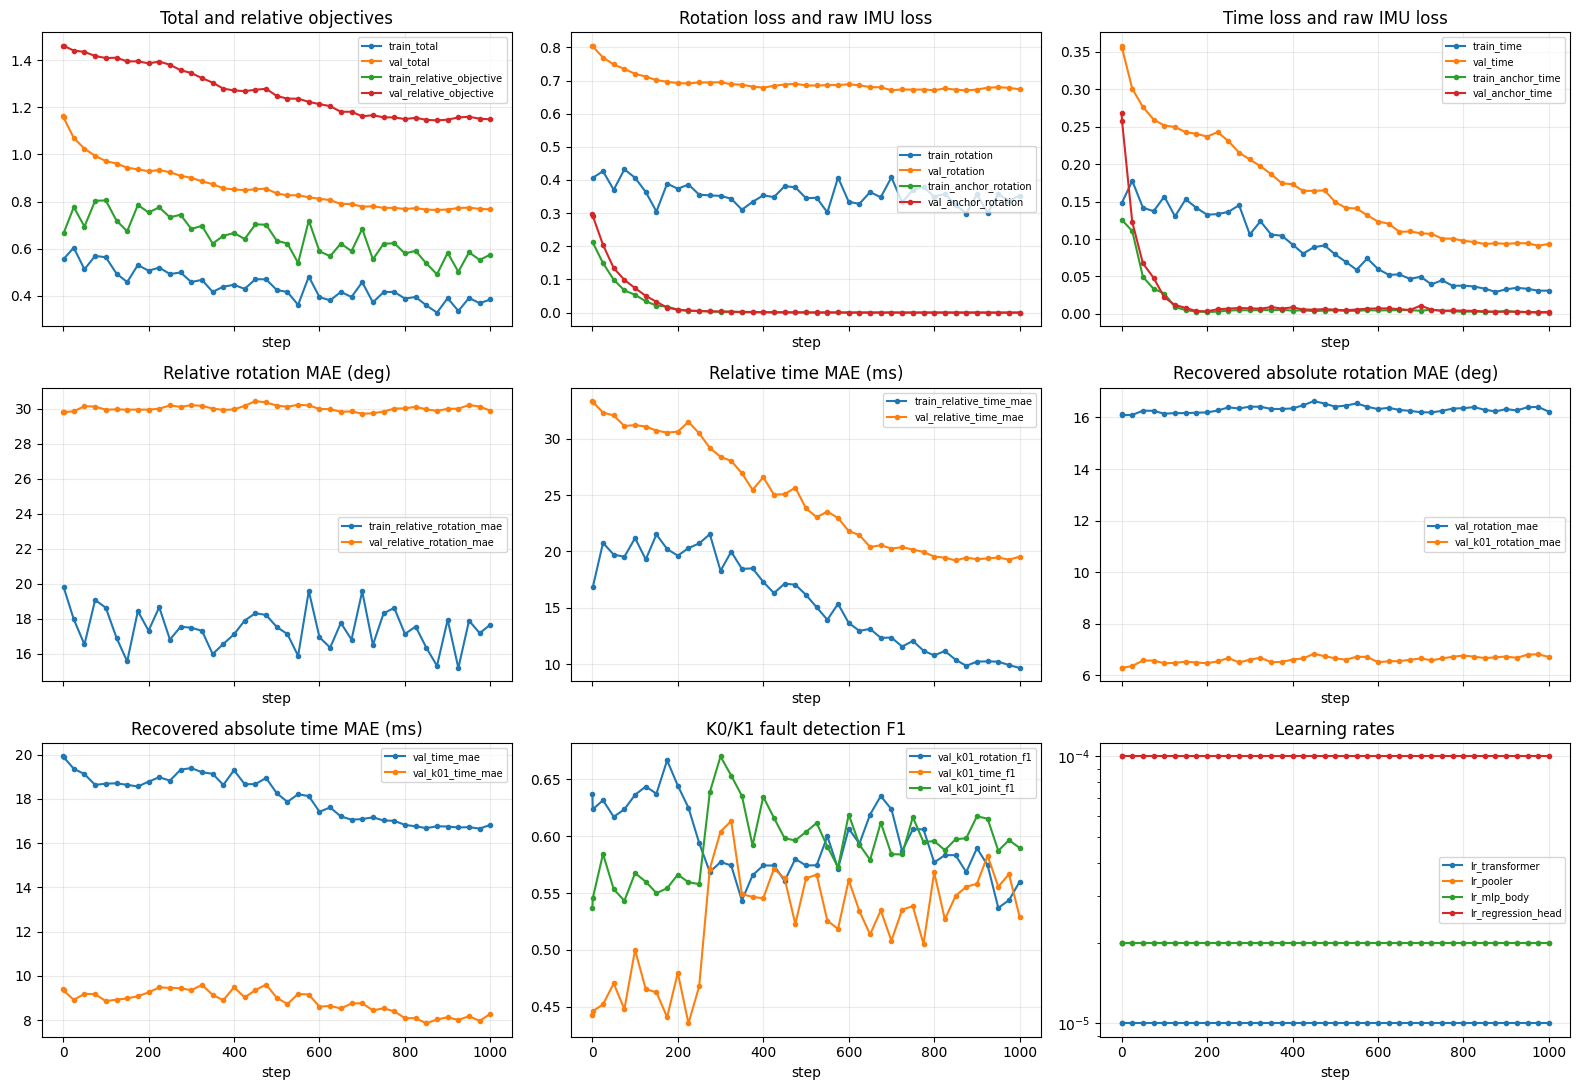

Restored untouched 002.27 initialization.


In [12]:
stochastic_history=[]
stochastic_monitor_indices=select_spread_indices_by_names(val_dataset,VAL_NAMES,STOCHASTIC_MONITOR_WINDOWS_PER_SEQUENCE,RANDOM_SEED+811)
# Assessment physical windows disjoint from stochastic monitoring windows.
assessment=[]
for seq in VAL_NAMES:
    available=np.setdiff1d(val_dataset.window_indices_for_sequence(seq),stochastic_monitor_indices)
    n=min(STOCHASTIC_ASSESSMENT_WINDOWS_PER_SEQUENCE,len(available))
    if n: assessment.extend(available[np.linspace(0,len(available)-1,n,dtype=int)].tolist())
stochastic_assessment_indices=np.asarray(assessment,dtype=int)
assert len(stochastic_assessment_indices) and not np.intersect1d(stochastic_assessment_indices,stochastic_monitor_indices).size

if RUN_STOCHASTIC_TEST and not RESUME_TRAINING:
    model.load_state_dict(initial_state,strict=True)
    diagnostic_optimizer=make_optimizer(model)
    rng_pool=np.random.default_rng(RANDOM_SEED+812)
    diag_train_indices=rng_pool.choice(len(train_dataset),min(STOCHASTIC_PHYSICAL_WINDOWS,len(train_dataset)),replace=False)
    monitor_seed=VALIDATION_AUG_SEED+119
    assert STOCHASTIC_STEPS>=1 and STOCHASTIC_PRINT_EVERY>=1
    try:
        df,losses=evaluate_cases(model,val_dataset,stochastic_monitor_indices,split_seed=monitor_seed)
        metrics=summarize_monitor(df,losses); del df
        stochastic_history.append(history_row('step',0,{},metrics,diagnostic_optimizer))
        print_monitor('Initial (raw 002.27 heads interpreted as relative)',metrics)
        best,best_abs=metrics['relative_objective'],metrics['absolute_objective']
        save_relative_checkpoint(STOCHASTIC_BEST_PATH,model,diagnostic_optimizer,None,0,metrics)
        save_relative_checkpoint(STOCHASTIC_BEST_ABSOLUTE_PATH,model,diagnostic_optimizer,None,0,metrics)
        running={}; running_n=0
        for step in range(1,STOCHASTIC_STEPS+1):
            rng=np.random.default_rng(RANDOM_SEED+777_000+step)
            chosen=rng.choice(diag_train_indices,min(PHYSICAL_WINDOWS_PER_UPDATE,len(diag_train_indices)),replace=False)
            raw=window_batch_to(collate_windows([train_dataset[int(i)] for i in chosen]),DEVICE,dtype=MODEL_DTYPE)
            physical=fixed_seeded_physical(raw,TRAIN_AUG_SEED+step*7)
            cases=sample_fault_cases(len(chosen),rng)
            train=train_case_batch(model,diagnostic_optimizer,physical,cases)
            for k,v in train.items(): running[k]=running.get(k,0.)+v*len(cases)
            running_n+=len(cases)
            del raw,physical,cases
            if step==1 or step%STOCHASTIC_PRINT_EVERY==0 or step==STOCHASTIC_STEPS:
                train={k:v/running_n for k,v in running.items()}; running={}; running_n=0
                df,losses=evaluate_cases(model,val_dataset,stochastic_monitor_indices,split_seed=monitor_seed)
                metrics=summarize_monitor(df,losses); del df
                stochastic_history.append(history_row('step',step,train,metrics,diagnostic_optimizer))
                print_monitor(f'Step {step}/{STOCHASTIC_STEPS} train={train["total"]:.4f} (R={train["rotation"]:.4f}, T={train["time"]:.4f})',metrics)
                print('  LR',format_lrs(diagnostic_optimizer))
                if metrics['relative_objective']<best:
                    best=metrics['relative_objective']; save_relative_checkpoint(STOCHASTIC_BEST_PATH,model,diagnostic_optimizer,None,step,metrics)
                if metrics['absolute_objective']<best_abs:
                    best_abs=metrics['absolute_objective']; save_relative_checkpoint(STOCHASTIC_BEST_ABSOLUTE_PATH,model,diagnostic_optimizer,None,step,metrics)
                pd.DataFrame(stochastic_history).to_csv(RUN_DIR/'stochastic_history.csv',index=False)
        save_relative_checkpoint(STOCHASTIC_FINAL_PATH,model,diagnostic_optimizer,None,STOCHASTIC_STEPS,metrics)
    finally:
        model.load_state_dict(initial_state,strict=True)
        model.zero_grad(set_to_none=True)
        del diagnostic_optimizer
        clear_cuda()
    plot_history(stochastic_history,'step','stochastic_learning_curves.png')
    print('Restored untouched 002.27 initialization.')
else: print('Stochastic training skipped.')

## 13. Independent stochastic checkpoint assessment and report helpers

002.27 | val total=0.5950 relative=0.8925 | relative R=21.87° T=21.99ms | absolute R=13.01° T=15.03ms | K01 absolute R=5.55° T=6.42ms | K01 F1 R=0.709 T=0.570 | raw IMU R=11.37° T=21.05ms
002.27 + medoid | val total=0.5950 relative=0.8925 | relative R=21.87° T=21.99ms | absolute R=13.47° T=15.59ms | K01 absolute R=5.44° T=6.12ms | K01 F1 R=0.711 T=0.572 | raw IMU R=11.37° T=21.05ms
relative init | val total=0.9825 relative=1.2132 | relative R=25.08° T=32.85ms | absolute R=14.48° T=21.05ms | K01 absolute R=6.23° T=7.90ms | K01 F1 R=0.616 T=0.477 | raw IMU R=11.37° T=21.05ms
stochastic_best | val total=0.6248 relative=0.9355 | relative R=25.67° T=18.67ms | absolute R=14.70° T=18.16ms | K01 absolute R=6.17° T=7.56ms | K01 F1 R=0.598 T=0.505 | raw IMU R=0.79° T=2.75ms
stochastic_best_absolute | val total=0.6293 relative=0.9419 | relative R=25.71° T=19.07ms | absolute R=14.75° T=18.19ms | K01 absolute R=6.22° T=7.39ms | K01 F1 R=0.608 T=0.531 | raw IMU R=0.72° T=3.12ms
stochastic_final | va

,checkpoint,relative_rotation_mae,relative_time_mae,rotation_mae,time_mae,k01_rotation_mae,k01_time_mae,k01_rotation_f1,k01_time_f1,k01_joint_f1
0,002.27,21.867,21.987,13.013,15.031,5.549,6.422,0.709,0.570,0.678
1,002.27 + medoid,21.867,21.987,13.468,15.588,5.440,6.118,0.711,0.572,0.675
2,relative init,25.084,32.847,14.481,21.054,6.235,7.899,0.616,0.477,0.550
3,stochastic_best,25.668,18.665,14.701,18.156,6.175,7.559,0.598,0.505,0.584
4,stochastic_best_absolute,25.708,19.071,14.749,18.193,6.219,7.392,0.608,0.531,0.601
5,stochastic_final,25.390,18.690,14.579,18.346,6.215,7.828,0.620,0.496,0.578


,scope,sensor,n,relative_n,relative_rotation_mae,relative_rotation_p90,relative_time_mae,absolute_rotation_mae,absolute_rotation_p90,absolute_time_mae,oracle_rotation_mae,oracle_time_mae,checkpoint
5,K01,imu,256,0,NaN,NaN,NaN,3.824,6.567,1.832,0.000,0.000,002.27
6,K01,lidar,256,256,9.374,11.378,10.099,5.751,6.784,9.098,9.374,10.099,002.27
7,K01,lidar_right,256,256,10.684,12.033,9.829,7.074,5.744,8.336,10.684,9.829,002.27
29,K01,imu,256,0,NaN,NaN,NaN,3.991,6.962,2.731,0.000,0.000,002.27 + medoid
30,K01,lidar,256,256,9.374,11.378,10.099,5.482,5.742,8.133,9.374,10.099,002.27 + medoid
31,K01,lidar_right,256,256,10.684,12.033,9.829,6.845,5.770,7.490,10.684,9.829,002.27 + medoid
53,K01,imu,256,0,NaN,NaN,NaN,6.362,3.914,8.006,0.000,0.000,relative init
54,K01,lidar,256,256,11.759,30.070,15.596,5.489,5.835,8.254,11.759,15.596,relative init
55,K01,lidar_right,256,256,13.086,32.232,15.026,6.854,5.744,7.436,13.086,15.026,relative init
77,K01,imu,256,0,NaN,NaN,NaN,6.377,3.736,5.117,0.000,0.000,stochastic_best


,scope,sensor,task,n,tp,fp,fn,tn,precision,recall,f1,specificity,accuracy,prevalence,ap,auroc,false_positive_rate,checkpoint
12,K01,all,joint,768,145,122,16,485,0.543,0.901,0.678,0.799,0.820,0.210,0.908,0.958,0.201,002.27
13,K01,all,rotation,768,79,53,12,624,0.598,0.868,0.709,0.922,0.915,0.118,0.857,0.963,0.078,002.27
14,K01,all,time,768,96,131,14,527,0.423,0.873,0.570,0.801,0.811,0.143,0.872,0.952,0.199,002.27
48,K2,all,joint,576,214,22,104,236,0.907,0.673,0.773,0.915,0.781,0.552,0.906,0.851,0.085,002.27
49,K2,all,rotation,576,121,40,61,354,0.752,0.665,0.706,0.898,0.825,0.316,0.791,0.794,0.102,002.27
50,K2,all,time,576,132,59,83,302,0.691,0.614,0.650,0.837,0.753,0.373,0.794,0.810,0.163,002.27
60,K3,all,joint,576,233,6,253,84,0.975,0.479,0.643,0.933,0.550,0.844,0.947,0.745,0.067,002.27
61,K3,all,rotation,576,145,35,129,267,0.806,0.529,0.639,0.884,0.715,0.476,0.770,0.692,0.116,002.27
62,K3,all,time,576,138,58,188,192,0.704,0.423,0.529,0.768,0.573,0.566,0.753,0.627,0.232,002.27
84,K01,all,joint,768,140,114,21,493,0.551,0.870,0.675,0.812,0.824,0.210,0.904,0.954,0.188,002.27 + medoid


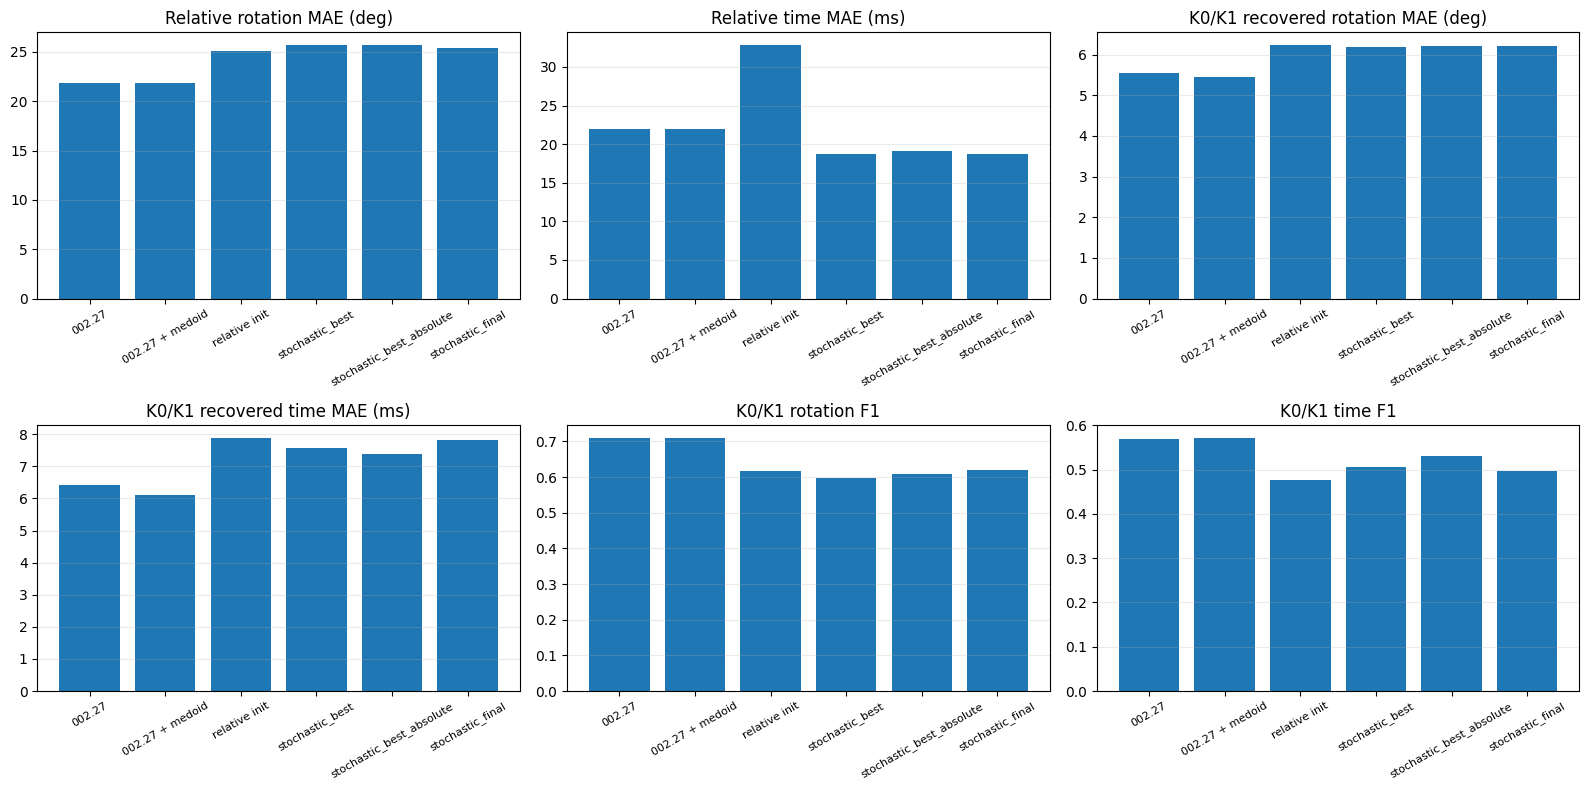

In [14]:
BASELINE_SPECS={'002.27':(None,'absolute'),'002.27 + medoid':(None,'absolute_medoid'),'relative init':(None,'relative')}


def report_tables(df):
    regression=[]; detection=[]
    for scope,part in [('all',df),('K01',df[df.fault_count.isin((0,1))]), *((f'K{k}',df[df.fault_count==k]) for k in FAULT_COUNTS)]:
        if part.empty: continue
        for sensor,g in [('all',part),*((k,part[part.sensor==k]) for k in CALIBRATION_KEYS)]:
            if g.empty: continue
            r=g[g.sensor!=REFERENCE_KEY]
            regression.append(dict(scope=scope,sensor=sensor,n=len(g),relative_n=len(r),relative_rotation_mae=r.relative_residual_deg.mean(),relative_rotation_p90=r.relative_residual_deg.quantile(.9),relative_time_mae=r.relative_time_residual_ms.abs().mean(),absolute_rotation_mae=g.residual.mean(),absolute_rotation_p90=g.residual.quantile(.9),absolute_time_mae=g.tau_residual_ms.abs().mean(),oracle_rotation_mae=g.oracle_residual_deg.mean(),oracle_time_mae=g.oracle_tau_residual_ms.abs().mean()))
            for task in TASKS:
                score=g.correction.to_numpy(float)/GT_ROT_TOL_DEG if task=='rotation' else g.delta_tau_ms.abs().to_numpy(float)/GT_TAU_TOL_MS if task=='time' else np.maximum(g.correction.to_numpy(float)/GT_ROT_TOL_DEG,g.delta_tau_ms.abs().to_numpy(float)/GT_TAU_TOL_MS)
                detection.append(dict(scope=scope,sensor=sensor,task=task,**metrics_for_scores(g[f'target_{task}'],score,score>1.)))
    return pd.DataFrame(regression),pd.DataFrame(detection)


def assess_checkpoints(specs,dataset,indices,split_seed,prefix):
    probe=make_initial_model(); summaries=[]; regression_tables=[]; detection_tables=[]
    expected=None
    try:
        for label,(path,policy) in specs.items():
            if path is None: probe.load_state_dict(initial_state,strict=True)
            else: load_relative_checkpoint(path,probe)
            df,losses=evaluate_cases(probe,dataset,indices,split_seed=split_seed,policy=policy)
            matched=df[['case_id','physical_index','sensor','fault_count','fault_mode','true_rotation_deg','true_tau_ms','relative_target_deg','relative_target_tau_ms']]
            if expected is None: expected=matched.copy()
            else: pd.testing.assert_frame_equal(expected,matched,check_exact=False,atol=1e-5,rtol=0.)
            m=summarize_monitor(df,losses)
            print_monitor(label,m)
            summaries.append(dict(checkpoint=label,policy=policy,**m))
            reg,det=report_tables(df)
            regression_tables.append(reg.assign(checkpoint=label)); detection_tables.append(det.assign(checkpoint=label))
            df.to_csv(RUN_DIR/f'{prefix}_{label.replace(" ","_").replace("+","plus")}_scores.csv',index=False)
            del df,matched
    finally:
        del probe
        clear_cuda()
    summary=pd.DataFrame(summaries); reg=pd.concat(regression_tables,ignore_index=True); det=pd.concat(detection_tables,ignore_index=True)
    for table,suffix in ((summary,'summary'),(reg,'regression'),(det,'detection')): table.to_csv(RUN_DIR/f'{prefix}_{suffix}.csv',index=False)
    cols=['checkpoint','relative_rotation_mae','relative_time_mae','rotation_mae','time_mae','k01_rotation_mae','k01_time_mae','k01_rotation_f1','k01_time_f1','k01_joint_f1']
    display(summary[cols].round(3))
    display(reg[(reg.scope=='K01') & (reg.sensor!='all')].round(3))
    display(det[(det.sensor=='all') & (det.scope.isin(('K01','K2','K3')))].round(3))
    fig,axes=plt.subplots(2,3,figsize=(16,8))
    for ax,field,title in zip(axes.flat,['relative_rotation_mae','relative_time_mae','k01_rotation_mae','k01_time_mae','k01_rotation_f1','k01_time_f1'],['Relative rotation MAE (deg)','Relative time MAE (ms)','K0/K1 recovered rotation MAE (deg)','K0/K1 recovered time MAE (ms)','K0/K1 rotation F1','K0/K1 time F1']):
        ax.bar(summary.checkpoint,summary[field]); ax.set_title(title); ax.tick_params(axis='x',rotation=30,labelsize=8); ax.grid(axis='y',alpha=.25)
    finish_figure(fig,f'{prefix}_comparison.png')
    return summary,reg,det

if RUN_STOCHASTIC_CHECKPOINT_EVALUATION and not RESUME_TRAINING:
    stochastic_specs={**BASELINE_SPECS,'stochastic_best':(STOCHASTIC_BEST_PATH,'relative'),'stochastic_best_absolute':(STOCHASTIC_BEST_ABSOLUTE_PATH,'relative'),'stochastic_final':(STOCHASTIC_FINAL_PATH,'relative')}
    stochastic_summary,stochastic_regression,stochastic_detection=assess_checkpoints(stochastic_specs,val_dataset,stochastic_assessment_indices,VALIDATION_AUG_SEED+719,'stochastic_assessment')

## 14. Full training (fresh 002.27 initialization, not stochastic weights)

In [26]:
training_history=[]
if RUN_FULL_TRAINING:
    model.load_state_dict(initial_state,strict=True)
    optimizer=make_optimizer(model)
    scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode='min',factor=LR_REDUCTION_FACTOR,patience=LR_PATIENCE_EPOCHS,min_lr=MIN_LR)
    df,losses=evaluate_cases(model,val_dataset,monitor_val_indices,split_seed=VALIDATION_AUG_SEED)
    initial_metrics=summarize_monitor(df,losses); del df
    print_monitor('Initial relative interpretation',initial_metrics)
    start_epoch,global_step=0,0
    paths={'relative_objective':BEST_CHECKPOINT_PATH,'absolute_objective':BEST_ABSOLUTE_PATH}
    best_scores={k:float(initial_metrics[k]) for k in paths}
    if RESUME_TRAINING:
        state=load_relative_checkpoint(LAST_CHECKPOINT_PATH,model)
        optimizer.load_state_dict(state['optimizer_state_dict']); scheduler.load_state_dict(state['scheduler_state_dict'])
        start_epoch,global_step=int(state['step']),int(state['global_step']); best_scores=state['best_scores']
        train_shuffle_generator.set_state(state['train_shuffle_state']); torch.set_rng_state(state['torch_rng_state'])
        if DEVICE.type=='cuda' and state['cuda_rng_state']: torch.cuda.set_rng_state_all(state['cuda_rng_state'])
        history_path=RUN_DIR/'training_history.csv'
        if history_path.is_file(): training_history=pd.read_csv(history_path).query('epoch <= @start_epoch').to_dict('records')
        del state
    else:
        if any(p.exists() for p in (*paths.values(),LAST_CHECKPOINT_PATH)): raise FileExistsError('Full-training checkpoints exist. Change RUN_NAME or set RESUME_TRAINING=True.')
        train_shuffle_generator.manual_seed(RANDOM_SEED+25); torch.manual_seed(RANDOM_SEED+89)
        if DEVICE.type=='cuda': torch.cuda.manual_seed_all(RANDOM_SEED+89)
        training_history.append(history_row('epoch',0,{},initial_metrics,optimizer))
        for path in (*paths.values(),LAST_CHECKPOINT_PATH): save_relative_checkpoint(path,model,optimizer,scheduler,0,initial_metrics,best_scores,0)
        pd.DataFrame(training_history).to_csv(RUN_DIR/'training_history.csv',index=False)
    for epoch in range(start_epoch,NUM_EPOCHS):
        print(f'\nEpoch {epoch+1}/{NUM_EPOCHS} | LR {format_lrs(optimizer)}',flush=True)
        train,global_step=run_train_epoch(model,optimizer,epoch,global_step)
        df,losses=evaluate_cases(model,val_dataset,monitor_val_indices,split_seed=VALIDATION_AUG_SEED)
        val=summarize_monitor(df,losses); del df
        previous=lr_values(optimizer); scheduler.step(val['relative_objective'])
        row=history_row('epoch',epoch+1,train,val,optimizer); row.update(global_step=global_step,**{f'{k}_before':v for k,v in previous.items()})
        training_history.append(row)
        print_monitor(f'Epoch {epoch+1} train={train["total"]:.4f} relative={train["relative_objective"]:.4f} R={train["rotation"]:.4f} T={train["time"]:.4f}',val)
        # print('  LR after scheduler:',format_lrs(optimizer),flush=True)
        # print('  Train K fractions:',[round(train[f'k{k}_fraction'],3) for k in FAULT_COUNTS])
        improved=[k for k in paths if np.isfinite(val[k]) and val[k]<best_scores[k]]
        for k in improved: best_scores[k]=float(val[k])
        for k in improved:
            save_relative_checkpoint(paths[k],model,optimizer,scheduler,epoch+1,val,best_scores,global_step); print('  Saved',paths[k].name)
        save_relative_checkpoint(LAST_CHECKPOINT_PATH,model,optimizer,scheduler,epoch+1,val,best_scores,global_step)
        pd.DataFrame(training_history).to_csv(RUN_DIR/'training_history.csv',index=False)
        clear_cuda()
    plot_history(training_history,'epoch','full_training_learning_curves.png')
else: print('Full training disabled; saved checkpoints can still be evaluated.')

Initial relative interpretation | val total=0.9846 relative=1.2025 | relative R=25.28° T=31.95ms | absolute R=14.04° T=19.63ms | K01 absolute R=5.33° T=8.47ms | K01 F1 R=0.673 T=0.473 | raw IMU R=12.93° T=20.50ms

Epoch 1/200 | LR transformer=1.00e-05 | pooler=2.00e-05 | mlp_body=2.00e-05 | regression_head=1.00e-04
Epoch 1 train=0.5334 relative=0.7632 R=0.3771 T=0.1563 | val total=0.7685 relative=1.1492 | relative R=25.46° T=29.64ms | absolute R=14.24° T=18.15ms | K01 absolute R=5.34° T=8.50ms | K01 F1 R=0.691 T=0.491 | raw IMU R=1.79° T=1.82ms
  Saved best.pt

Epoch 2/200 | LR transformer=1.00e-05 | pooler=2.00e-05 | mlp_body=2.00e-05 | regression_head=1.00e-04
Epoch 2 train=0.4672 relative=0.6982 R=0.3601 T=0.1071 | val total=0.6862 relative=1.0267 | relative R=25.49° T=23.42ms | absolute R=14.35° T=17.97ms | K01 absolute R=5.37° T=7.85ms | K01 F1 R=0.630 T=0.598 | raw IMU R=1.08° T=3.72ms
  Saved best.pt
  Saved best_absolute.pt

Epoch 3/200 | LR transformer=1.00e-05 | pooler=2.00e-

KeyboardInterrupt: 

## 15. Detailed full-run evaluation (matched validation, optional untouched test)

002.27 | val total=0.5955 relative=0.8932 | relative R=22.03° T=21.23ms | absolute R=12.95° T=14.29ms | K01 absolute R=5.47° T=6.17ms | K01 F1 R=0.724 T=0.594 | raw IMU R=11.32° T=21.40ms
002.27 + medoid | val total=0.5955 relative=0.8932 | relative R=22.03° T=21.23ms | absolute R=13.29° T=15.08ms | K01 absolute R=5.37° T=5.72ms | K01 F1 R=0.727 T=0.611 | raw IMU R=11.32° T=21.40ms
relative init | val total=0.9917 relative=1.2284 | relative R=25.37° T=32.84ms | absolute R=14.46° T=20.10ms | K01 absolute R=6.07° T=8.62ms | K01 F1 R=0.644 T=0.442 | raw IMU R=11.32° T=21.40ms
best | val total=0.4631 relative=0.6945 | relative R=21.68° T=11.62ms | absolute R=14.17° T=14.29ms | K01 absolute R=5.38° T=4.54ms | K01 F1 R=0.685 T=0.715 | raw IMU R=0.41° T=0.60ms
best_absolute | val total=0.4665 relative=0.6996 | relative R=21.67° T=11.71ms | absolute R=14.15° T=14.19ms | K01 absolute R=5.39° T=4.42ms | K01 F1 R=0.697 T=0.724 | raw IMU R=0.51° T=0.71ms
last | val total=0.4598 relative=0.6896 | r

,checkpoint,relative_rotation_mae,relative_time_mae,rotation_mae,time_mae,k01_rotation_mae,k01_time_mae,k01_rotation_f1,k01_time_f1,k01_joint_f1
0,002.27,22.029,21.232,12.946,14.290,5.468,6.166,0.724,0.594,0.693
1,002.27 + medoid,22.029,21.232,13.292,15.081,5.369,5.723,0.727,0.611,0.717
2,relative init,25.371,32.839,14.455,20.101,6.067,8.620,0.644,0.442,0.557
3,best,21.678,11.616,14.174,14.289,5.381,4.538,0.685,0.715,0.740
4,best_absolute,21.667,11.715,14.148,14.187,5.392,4.421,0.697,0.724,0.760
5,last,21.567,11.415,14.162,14.239,5.388,4.474,0.697,0.715,0.745


,scope,sensor,n,relative_n,relative_rotation_mae,relative_rotation_p90,relative_time_mae,absolute_rotation_mae,absolute_rotation_p90,absolute_time_mae,oracle_rotation_mae,oracle_time_mae,checkpoint
5,K01,imu,1376,0,NaN,NaN,NaN,3.831,4.595,2.114,0.000,0.000,002.27
6,K01,lidar,1376,1376,10.173,11.266,9.619,6.603,5.022,8.290,10.173,9.619,002.27
7,K01,lidar_right,1376,1376,9.556,10.799,9.567,5.970,5.795,8.094,9.556,9.567,002.27
29,K01,imu,1376,0,NaN,NaN,NaN,3.911,4.746,3.039,0.000,0.000,002.27 + medoid
30,K01,lidar,1376,1376,10.173,11.266,9.619,6.416,4.858,7.120,10.173,9.619,002.27 + medoid
31,K01,lidar_right,1376,1376,9.556,10.799,9.567,5.781,5.771,7.010,9.556,9.567,002.27 + medoid
53,K01,imu,1376,0,NaN,NaN,NaN,5.992,3.816,11.733,0.000,0.000,relative init
54,K01,lidar,1376,1376,12.291,29.356,18.423,6.425,4.913,7.199,12.291,18.423,relative init
55,K01,lidar_right,1376,1376,11.676,17.860,18.145,5.785,5.741,6.929,11.676,18.145,relative init
77,K01,imu,1376,0,NaN,NaN,NaN,3.704,4.290,2.714,0.000,0.000,best


,scope,sensor,task,n,tp,fp,fn,tn,precision,recall,f1,specificity,accuracy,prevalence,ap,auroc,false_positive_rate,checkpoint
12,K01,all,joint,4128,761,583,91,2693,0.566,0.893,0.693,0.822,0.837,0.206,0.895,0.947,0.178,002.27
13,K01,all,rotation,4128,415,246,70,3397,0.628,0.856,0.724,0.932,0.923,0.117,0.859,0.954,0.068,002.27
14,K01,all,time,4128,514,649,54,2911,0.442,0.905,0.594,0.818,0.830,0.138,0.868,0.948,0.182,002.27
48,K2,all,joint,3096,1122,114,580,1280,0.908,0.659,0.764,0.918,0.776,0.550,0.900,0.843,0.082,002.27
49,K2,all,rotation,3096,631,182,347,1936,0.776,0.645,0.705,0.914,0.829,0.316,0.795,0.810,0.086,002.27
50,K2,all,time,3096,728,319,409,1640,0.695,0.640,0.667,0.837,0.765,0.367,0.792,0.799,0.163,002.27
60,K3,all,joint,3096,1229,47,1329,491,0.963,0.480,0.641,0.913,0.556,0.826,0.939,0.738,0.087,002.27
61,K3,all,rotation,3096,713,178,707,1498,0.800,0.502,0.617,0.894,0.714,0.459,0.753,0.673,0.106,002.27
62,K3,all,time,3096,778,275,937,1106,0.739,0.454,0.562,0.801,0.609,0.554,0.771,0.674,0.199,002.27
84,K01,all,joint,4128,761,510,91,2766,0.599,0.893,0.717,0.844,0.854,0.206,0.894,0.943,0.156,002.27 + medoid


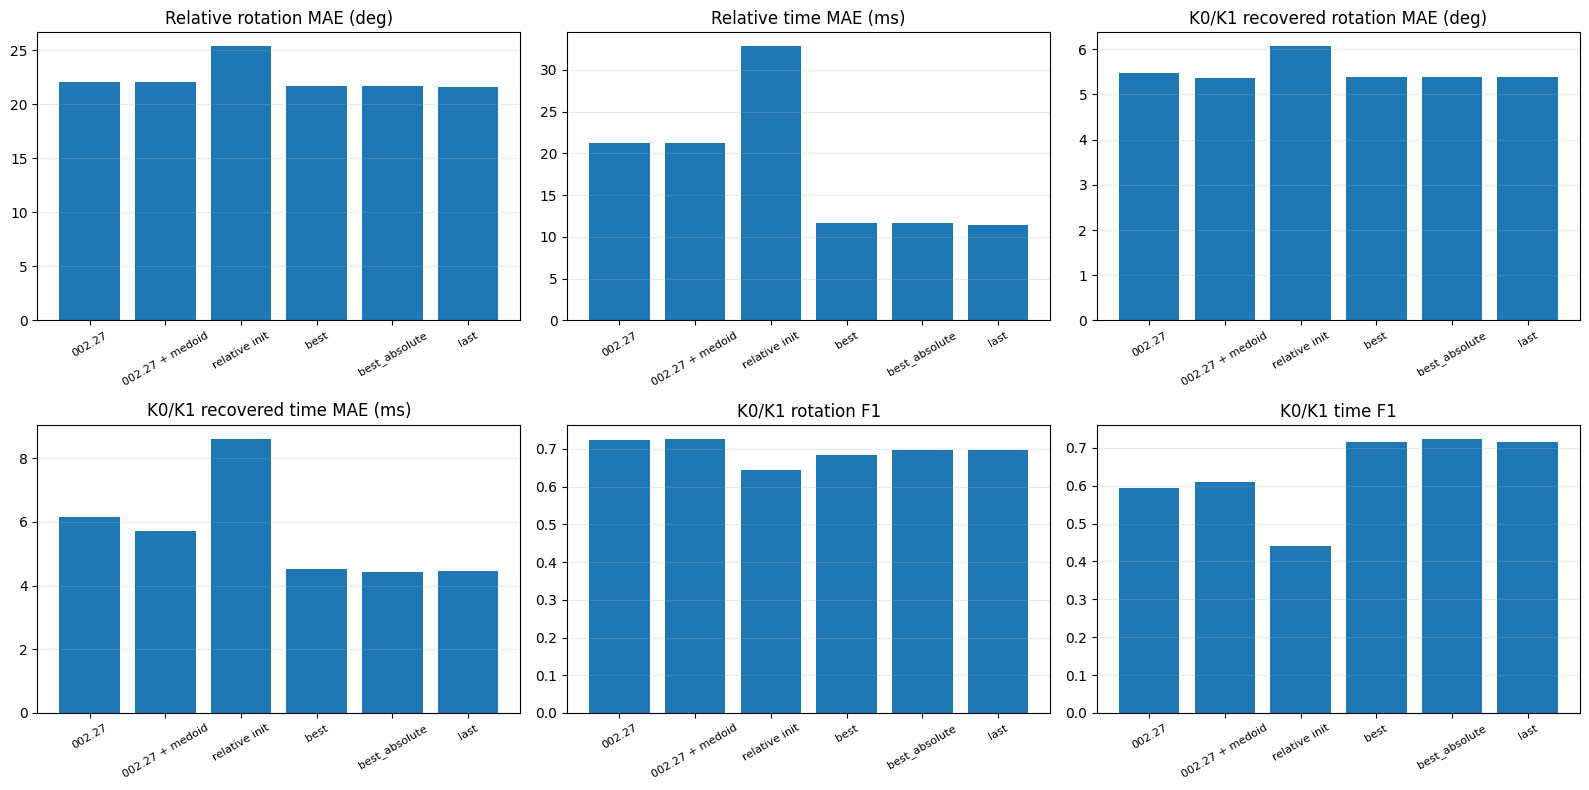

In [27]:
full_specs={**BASELINE_SPECS,'best':(BEST_CHECKPOINT_PATH,'relative'),'best_absolute':(BEST_ABSOLUTE_PATH,'relative'),'last':(LAST_CHECKPOINT_PATH,'relative')}
if RUN_DETAILED_EVALUATION:
    full_val_summary,full_val_regression,full_val_detection=assess_checkpoints(full_specs,val_dataset,detailed_val_indices,VALIDATION_AUG_SEED+351,'full_validation')
    if RUN_TEST_EVALUATION:
        full_test_summary,full_test_regression,full_test_detection=assess_checkpoints(full_specs,test_dataset,detailed_test_indices,TEST_AUG_SEED+351,'full_test')

## 16. Controlled K=1 single-window angle and time sweeps

All initial errors are independently injected once per physical window. No calibration estimate is propagated. F1 uses individual sensor decisions pooled over all windows. The zero-angle cases are clean controls, not K=1 positives. Relative error metrics exclude the reference head; absolute metrics include all three sensors. The selected-head residual and healthy-head drift are reported separately.

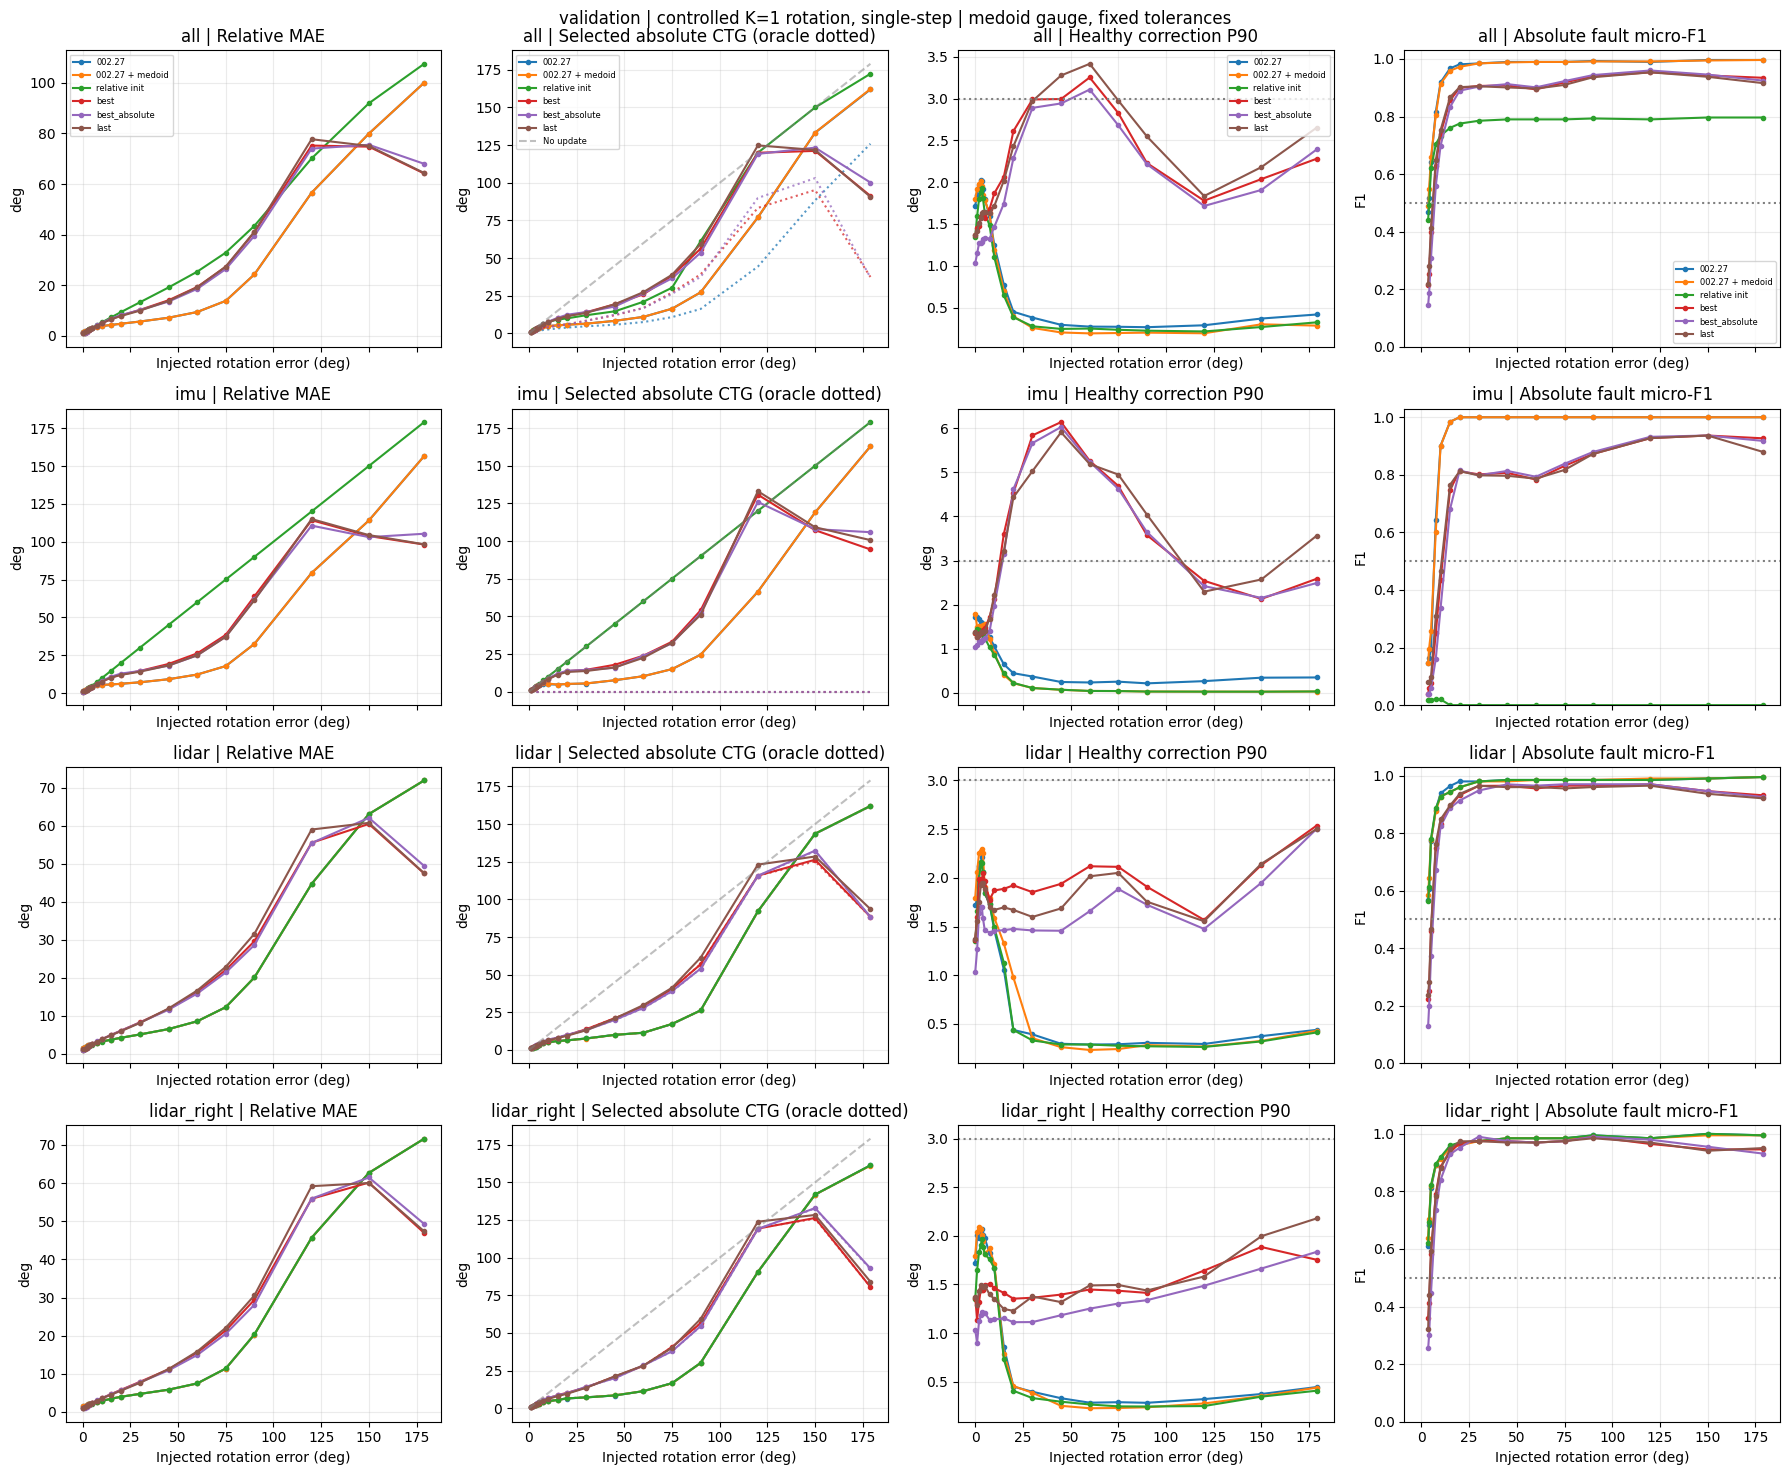

,checkpoint,sensor,magnitude,n_cases,exact,relative_mae,relative_p90,selected_residual_median,selected_residual_p90,selected_oracle_median,...,tn,precision,recall,f1,specificity,accuracy,prevalence,ap,auroc,false_positive_rate
0,002.27,all,0.0,48,0.896,1.564,2.655,NaN,NaN,NaN,...,139,0.000,NaN,NaN,0.965,0.965,0.000,NaN,NaN,0.035
1,002.27,all,1.0,288,0.906,1.735,2.911,1.032,2.178,0.895,...,837,0.000,NaN,NaN,0.969,0.969,0.000,NaN,NaN,0.031
2,002.27,all,2.0,288,0.882,2.093,3.241,1.856,2.880,1.215,...,830,0.000,NaN,NaN,0.961,0.961,0.000,NaN,NaN,0.039
3,002.27,all,3.0,288,0.726,2.443,3.842,2.512,3.545,1.439,...,784,0.000,NaN,NaN,0.907,0.907,0.000,NaN,NaN,0.093
4,002.27,all,3.5,288,0.323,2.610,4.196,2.863,3.862,1.534,...,556,0.825,0.326,0.468,0.965,0.752,0.333,0.633,0.753,0.035
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
394,last,all,75.0,288,0.802,27.385,65.366,38.916,69.996,26.550,...,519,0.835,1.000,0.910,0.901,0.934,0.333,0.999,0.999,0.099
395,last,all,90.0,288,0.865,41.150,98.110,59.381,102.400,41.245,...,537,0.881,1.000,0.937,0.932,0.955,0.333,0.999,1.000,0.068
396,last,all,120.0,288,0.903,77.709,163.359,124.818,167.698,93.116,...,548,0.911,1.000,0.954,0.951,0.968,0.333,1.000,1.000,0.049
397,last,all,150.0,288,0.868,75.042,165.203,121.795,170.824,87.539,...,538,0.883,1.000,0.938,0.934,0.956,0.333,0.999,1.000,0.066


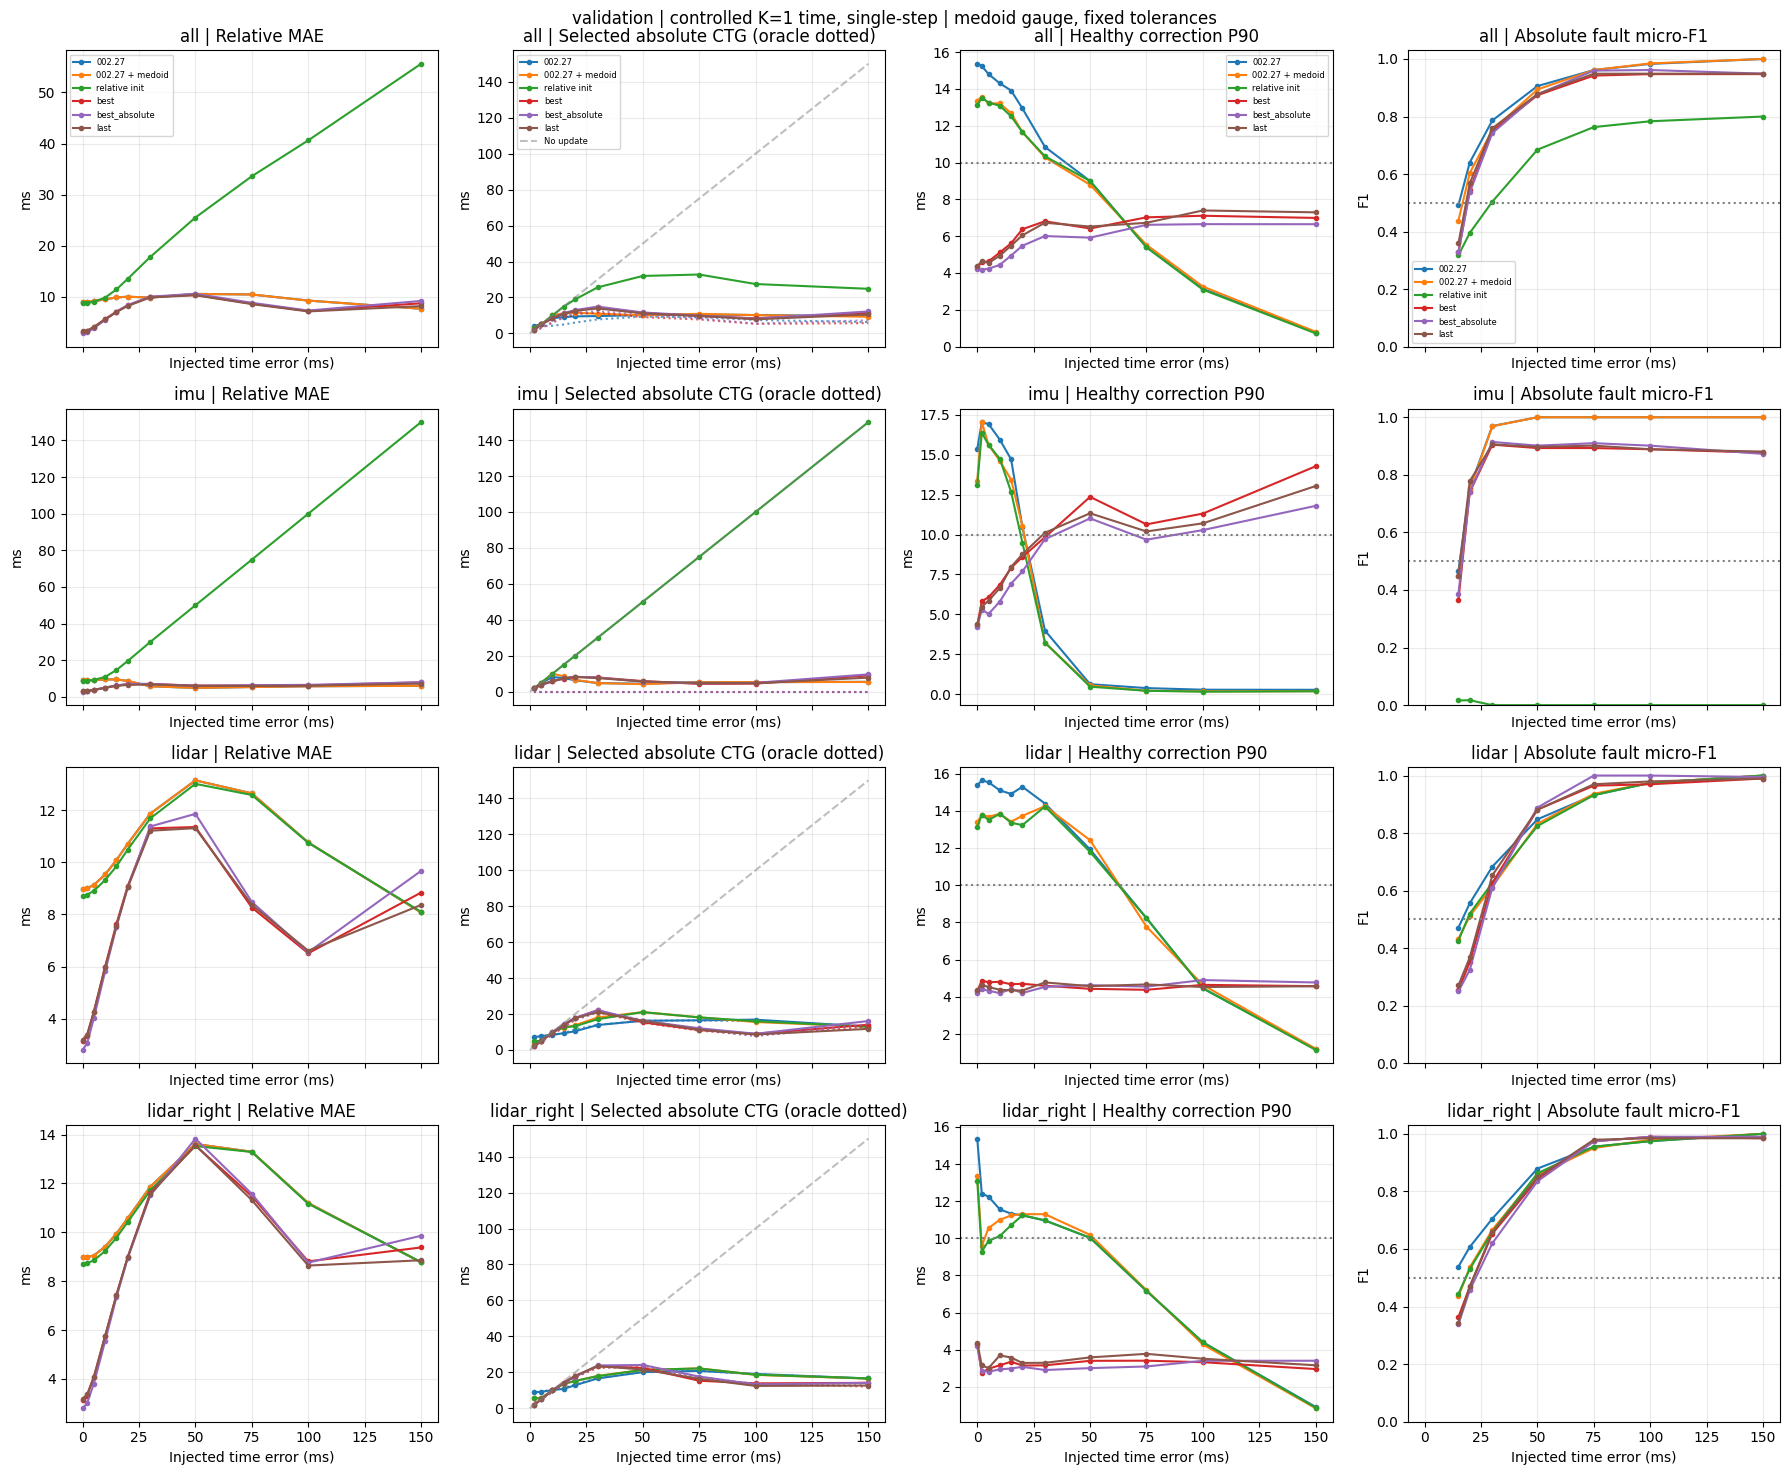

,checkpoint,sensor,magnitude,n_cases,exact,relative_mae,relative_p90,selected_residual_median,selected_residual_p90,selected_oracle_median,...,tn,precision,recall,f1,specificity,accuracy,prevalence,ap,auroc,false_positive_rate
0,002.27,all,0.0,48,0.354,8.984,17.469,NaN,NaN,NaN,...,111,0.000,NaN,NaN,0.771,0.771,0.000,NaN,NaN,0.229
1,002.27,all,2.0,576,0.361,9.004,17.732,4.184,15.225,3.818,...,1324,0.000,NaN,NaN,0.766,0.766,0.000,NaN,NaN,0.234
2,002.27,all,5.0,576,0.365,9.104,17.836,5.135,15.390,4.125,...,1316,0.000,NaN,NaN,0.762,0.762,0.000,NaN,NaN,0.238
3,002.27,all,10.0,576,0.351,9.478,18.695,8.463,16.573,4.244,...,1294,0.000,NaN,NaN,0.749,0.749,0.000,NaN,NaN,0.251
4,002.27,all,15.0,576,0.351,9.840,19.919,9.091,18.565,4.959,...,956,0.562,0.438,0.492,0.830,0.699,0.333,0.569,0.714,0.170
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
226,last,all,30.0,576,0.590,9.840,27.397,13.896,30.000,10.988,...,1094,0.870,0.674,0.759,0.950,0.858,0.333,0.830,0.853,0.050
227,last,all,50.0,576,0.771,10.278,30.177,11.168,43.535,9.336,...,1086,0.884,0.872,0.878,0.943,0.919,0.333,0.954,0.963,0.057
228,last,all,75.0,576,0.892,8.543,20.575,9.733,29.581,8.318,...,1092,0.905,0.997,0.949,0.948,0.964,0.333,0.999,0.999,0.052
229,last,all,100.0,576,0.892,7.108,18.038,7.826,21.921,5.434,...,1090,0.903,1.000,0.949,0.946,0.964,0.333,1.000,1.000,0.054


In [28]:
def controlled_summary(df,checkpoint,sweep):
    rows=[]
    amplitude='angle_deg' if sweep=='rotation' else 'injected_time_ms'
    for sensor in ('all',*CALIBRATION_KEYS):
        data=df if sensor=='all' else df[(df.selected_sensor==sensor)|(df.fault_count==0)]
        for magnitude,g in data.groupby(amplitude):
            fault=g[g.sensor==g.selected_sensor]; healthy=g[g.sensor!=g.selected_sensor]; rel=g[g.sensor!=REFERENCE_KEY]
            truth=g[f'target_{sweep}'].to_numpy(bool)
            score=g.correction.to_numpy(float)/GT_ROT_TOL_DEG if sweep=='rotation' else g.delta_tau_ms.abs().to_numpy(float)/GT_TAU_TOL_MS
            alarm=score>1.
            m=metrics_for_scores(truth,score,alarm)
            exact=pd.DataFrame(dict(case=g.case_id,correct=truth==alarm)).groupby('case').correct.all().mean()
            absolute_field='residual' if sweep=='rotation' else 'tau_residual_ms'
            relative_field='relative_residual_deg' if sweep=='rotation' else 'relative_time_residual_ms'
            oracle_field='oracle_residual_deg' if sweep=='rotation' else 'oracle_tau_residual_ms'
            correction_field='correction' if sweep=='rotation' else 'delta_tau_ms'
            rows.append(dict(checkpoint=checkpoint,sensor=sensor,magnitude=magnitude,n_cases=g.case_id.nunique(),exact=exact,relative_mae=rel[relative_field].abs().mean(),relative_p90=rel[relative_field].abs().quantile(.9),selected_residual_median=fault[absolute_field].abs().median(),selected_residual_p90=fault[absolute_field].abs().quantile(.9),selected_oracle_median=fault[oracle_field].abs().median(),healthy_correction_p90=healthy[correction_field].abs().quantile(.9),**{**m,'f1':m['f1'] if truth.any() else np.nan}))
    return pd.DataFrame(rows)


if RUN_CONTROLLED_SWEEP:
    sweep_dataset,sweep_names,sweep_split=(test_dataset,TEST_NAMES,'test') if RUN_TEST_EVALUATION else (val_dataset,VAL_NAMES,'validation')
    sweep_indices=select_spread_indices_by_names(sweep_dataset,sweep_names,SWEEP_WINDOWS_PER_SEQUENCE,RANDOM_SEED+900)
    sweep_seed=(TEST_AUG_SEED if RUN_TEST_EVALUATION else VALIDATION_AUG_SEED)+900
    probe=make_initial_model()
    try:
        for sweep in ('rotation','time'):
            reports=[]; expected=None
            for label,(path,policy) in full_specs.items():
                if path is None: probe.load_state_dict(initial_state,strict=True)
                else: load_relative_checkpoint(path,probe)
                df,_=evaluate_cases(probe,sweep_dataset,sweep_indices,split_seed=sweep_seed,policy=policy,controlled=sweep)
                matched=df[['case_id','physical_index','sensor','selected_sensor','axis_id','true_rotation_deg','true_tau_ms','relative_target_deg','relative_target_tau_ms']]
                if expected is None: expected=matched.copy()
                else: pd.testing.assert_frame_equal(expected,matched,check_exact=False,atol=1e-5,rtol=0.)
                df.to_csv(RUN_DIR/f'{sweep_split}_{sweep}_controlled_{label.replace(" ","_").replace("+","plus")}.csv',index=False)
                reports.append(controlled_summary(df,label,sweep)); del df,matched
            report=pd.concat(reports,ignore_index=True)
            report.to_csv(RUN_DIR/f'{sweep_split}_{sweep}_controlled_summary.csv',index=False)
            units='deg' if sweep=='rotation' else 'ms'
            tol=GT_ROT_TOL_DEG if sweep=='rotation' else GT_TAU_TOL_MS
            fig,axes=plt.subplots(4,4,figsize=(18,15),sharex=True)
            for row,sensor in enumerate(('all',*CALIBRATION_KEYS)):
                subset=report[report.sensor==sensor]
                for label,g in subset.groupby('checkpoint',sort=False):
                    g=g.sort_values('magnitude'); x=g.magnitude.to_numpy(float)
                    for col,field in enumerate(('relative_mae','selected_residual_median','healthy_correction_p90','f1')):
                        line,=axes[row,col].plot(x,g[field],'-o',markersize=3,label=label)
                        if col==1 and label in ('002.27','best','best_absolute'):
                            axes[row,col].plot(x,g.selected_oracle_median,':',color=line.get_color(),alpha=.75)
                axes[row,1].plot([0,max(subset.magnitude)],[0,max(subset.magnitude)],'--',color='gray',alpha=.5,label='No update')
                axes[row,2].axhline(tol,color='gray',linestyle=':')
                axes[row,3].axhline(.5,color='gray',linestyle=':'); axes[row,3].set_ylim(0,1.03)
                for col,title in enumerate(('Relative MAE','Selected absolute CTG (oracle dotted)','Healthy correction P90','Absolute fault micro-F1')):
                    ax=axes[row,col]; ax.set(title=f'{sensor} | {title}',xlabel=f'Injected {sweep} error ({units})',ylabel='F1' if col==3 else units); ax.grid(alpha=.25)
                    if row==0: ax.legend(fontsize=6)
            fig.suptitle(f'{sweep_split} | controlled K=1 {sweep}, single-step | medoid gauge, fixed tolerances')
            finish_figure(fig,f'{sweep_split}_{sweep}_controlled_comparison.png')
            display(report[report.sensor=='all'].round(3))
    finally:
        del probe; clear_cuda()

## Interpretation and next decisions

- Compare **002.27** vs **002.27 + medoid**: isolates post-processing with no training.
- Compare **002.27 + medoid** vs **best**: same gauge rule, different relative-learning formulation.
- Compare relative MAE and oracle absolute residual: whether relative alignment itself improved. The oracle uses the actual reference correction; its IMU residual is zero by construction and it is not deployable.
- Compare `best` vs `best_absolute`: primary selects relative accuracy across all K; secondary selects recovered absolute accuracy on K0/K1. Report K2/K3 separately: majority recovery can fail even for perfect relative predictions.
- Raw IMU correction is a diagnostic of identity supervision; it is never applied. K0 false alarms and selected/healthy residuals are evaluated with fixed 3° / 10 ms thresholds. No classification head or rollout is involved.
- `best.pt` stores *relative* outputs. Loading it with the original absolute-calibration updater would be incorrect; recover the gauge first. The checkpoint signature is intentionally distinct from older notebooks.
- To test strict N-1 supervision, set `IMU_IDENTITY_LOSS_WEIGHT=0.0` and a new `RUN_NAME`. Keep other settings fixed. To investigate explicit reference conditioning later, make a separate experiment.